# Entrenamiento del Modelo MLP con Validación Cruzada Temporal
**Proyecto Integrador · Aprendizaje Profundo**
Estación A001 — Brasília, DF · 2020–2026

---

## 1. Introducción

Con la mejor arquitectura de cada combinación (lag × horizonte), obtenida en el cuaderno 2, este cuaderno entrena el MLP multisalida y lo evalúa con las tres estrategias de validación cruzada de `timeseries-cv`. Como referencia se entrena además un `MLPRegressor` de scikit-learn con capas (64, 32) en los mismos folds.

La versión instalada de la librería (0.1.5) no entrega las particiones tal como las describe el enunciado. La tabla documenta qué produce cada función y cómo se usa aquí:

| Estrategia | Qué entrega `tsxv` 0.1.5 (`numJumps = 7`) | Folds usados en este cuaderno |
|---|---|---|
| **Group K-Fold** | 5 folds; una de cada cinco ventanas va a validación, de modo que la validación queda intercalada a lo largo de toda la serie | Los 5 folds de la librería, sin cambios |
| **Forward Chaining** | Un fold por origen (≈ 310): entrenamiento expansivo y una sola ventana de validación | Los orígenes se agrupan en 6 bloques consecutivos. El primero solo entrena; en cada uno de los otros 5, el modelo se entrena con el conjunto del primer origen del bloque y se valida con todas las ventanas del bloque |
| **K-Fold** | Un fold por ventana (≈ 310): deja una ventana fuera y entrena con las anteriores y las posteriores | 5 bloques contiguos de ventanas de validación; el entrenamiento incluye ventanas anteriores y posteriores al bloque |

En Forward Chaining y K-Fold se eliminan del entrenamiento las ventanas que comparten observaciones con el bloque de validación (purga); sin ese paso, el objetivo de una ventana de entrenamiento podría coincidir con el de una de validación. Group K-Fold se usa tal cual: sus ventanas de validación se solapan con las de entrenamiento vecinas, lo que en principio la expone a un sesgo optimista (sección 7). Con 5 folds, cada fold tiene entre 30 y 65 ventanas de validación, suficientes para calcular el RMSE por horizonte y la prueba BDS.

Las métricas son **MAPE, MAE, RMSE, MSE y el p-valor de la prueba BDS** sobre los residuos del horizonte $h = 1$, calculadas en el **conjunto de validación** de cada fold. El hold-out temporal se evalúa por separado con el modelo final, reentrenado con toda la serie previa al hold-out.

---

## 2. Importar librerías

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import gc
import ast
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import tensorflow as tf
import joblib
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from statsmodels.tsa.stattools import bds

from tsxv.splitTrainVal import (
    split_train_val_groupKFold,
    split_train_val_forwardChaining,
    split_train_val_kFold,
)

tf.get_logger().setLevel('ERROR')
tf.keras.utils.set_random_seed(42)

plt.rcParams.update({
    'figure.dpi': 120,
    'axes.prop_cycle': matplotlib.cycler('color', ['#000000', '#444444', '#888888', '#bbbbbb']),
    'axes.grid': True, 'grid.alpha': 0.3,
    'font.size': 10, 'axes.titlesize': 11,
})

BASE_DIR    = os.path.dirname(os.getcwd())
DATA_PATH   = os.path.join(BASE_DIR, 'data', 'dataset.csv')
RESULTS_DIR = os.path.join(BASE_DIR, 'results')
APP_DIR     = os.path.join(BASE_DIR, 'app')
FIGS_DIR    = os.path.join(os.getcwd(), 'figs')
LOG_PATH    = os.path.join(RESULTS_DIR, 'progreso_entrenamiento.log')
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(APP_DIR, exist_ok=True)
os.makedirs(FIGS_DIR, exist_ok=True)

print(f'TensorFlow: {tf.__version__}')

TensorFlow: 2.21.0


## 3. Cargar datos y arquitecturas

Se carga el dataset procesado y el resumen de mejores arquitecturas generado en el cuaderno 2. Se usa la misma ventana de 2020 a 2026 del cuaderno 2 (sección 3) y el mismo hold-out temporal.

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=['date'])
df = df.sort_values('date').reset_index(drop=True)

# Misma ventana que el cuaderno 2: 2020-2026.
df = df[df.date >= '2020-01-01'].reset_index(drop=True)

y_full = df['wind_speed'].values.astype(np.float32)
fechas = df['date'].values

LAGS_LIST     = [7, 14, 21, 28]
HORIZONS_LIST = [7, 14, 21, 28]
N_STEPS_JUMP  = 7
HOLDOUT_FRAC  = 0.10
K_FOLDS       = 5
EPOCHS_FINAL  = 100
BATCH_SIZE    = 32
DROPOUT_RATE  = 0.5

n_hold        = max(int(len(y_full) * HOLDOUT_FRAC), 2 * max(HORIZONS_LIST))
serie_cv      = y_full[:-n_hold]
serie_holdout = y_full[-n_hold:]
fechas_cv     = fechas[:len(serie_cv)]
fechas_ho     = fechas[len(serie_cv):]

arch_df = pd.read_csv(os.path.join(RESULTS_DIR, 'best_architecture_summary.csv'))


def get_best_arch(lag, H):
    row = arch_df[(arch_df.lag == lag) & (arch_df.horizonte == H)].iloc[0]
    return ast.literal_eval(row['arquitectura']), ast.literal_eval(row['dropout_mask'])


print(f'Serie CV: {len(serie_cv)} ({pd.Timestamp(fechas_cv[0]).date()} a {pd.Timestamp(fechas_cv[-1]).date()})')
print(f'Hold-out: {len(serie_holdout)} ({pd.Timestamp(fechas_ho[0]).date()} a {pd.Timestamp(fechas_ho[-1]).date()})')
display(arch_df)

Serie CV: 2247 (2020-01-01 a 2026-02-24)
Hold-out: 249 (2026-02-25 a 2026-10-31)


,lag,horizonte,arquitectura,dropout_mask,best_val_rmse,gap_ratio,holdout_rmse,balanceado
0,7,7,"(64, 256, 128)","(False, True, True)",0.9504,0.0297,0.9623,True
1,7,14,"(64, 128, 256)","(False, False, True)",0.9912,0.0657,0.9797,True
2,7,21,"(256, 32, 128)","(False, True, True)",1.0026,0.0213,0.9792,True
3,7,28,"(256, 32, 128)","(False, True, True)",1.0168,0.0274,0.9874,True
4,14,7,"(64, 256, 128)","(False, True, True)",0.9504,0.0479,0.9602,True
5,14,14,"(64, 128, 256)","(False, False, True)",0.9998,0.1328,0.9843,True
6,14,21,"(64, 128, 256)","(False, False, True)",1.0142,0.0855,0.9872,True
7,14,28,"(256, 32, 256)","(False, True, True)",1.0145,0.0517,0.9902,True
8,21,7,"(256, 32, 256)","(False, True, True)",0.9672,0.0853,0.9711,True
9,21,14,"(64, 256, 128)","(False, True, True)",1.0060,0.1076,0.9949,True


## 4. Funciones auxiliares: particiones, modelo y métricas

`particiones` llama a la función de `tsxv` sobre la serie de **índices** temporales (0, 1, 2, …) en lugar de sobre los valores. Así cada ventana conserva su posición en el tiempo, lo que permite aplicar la purga, fechar las predicciones y dibujar el esquema de cada estrategia. Los valores se recuperan después con `serie_cv[indices]`. La prueba BDS se calcula con `statsmodels.tsa.stattools.bds` (dimensión de inmersión 2).

In [3]:
SPLIT_FUNCTIONS = {
    'groupKFold'      : split_train_val_groupKFold,
    'forwardChaining' : split_train_val_forwardChaining,
    'kFold'           : split_train_val_kFold,
}


def registrar(msg):
    linea = f'[{time.strftime("%H:%M:%S")}] {msg}'
    print(linea, flush=True)
    with open(LOG_PATH, 'a', encoding='utf-8') as f:
        f.write(linea + '\n')


def particiones(estrategia, n_obs, lag, H, jump=N_STEPS_JUMP, k=K_FOLDS):
    """Lista de folds (X, y, Xcv, ycv) expresados como índices temporales."""
    idx = np.arange(n_obs)
    X, y, Xcv, ycv = SPLIT_FUNCTIONS[estrategia](idx, numInputs=lag, numOutputs=H, numJumps=jump)
    folds = sorted(X)
    if estrategia == 'groupKFold':
        return [(X[f], y[f], Xcv[f], ycv[f]) for f in folds]
    if estrategia == 'forwardChaining':
        bordes, bloques = np.linspace(0, len(folds), k + 2).astype(int), range(1, k + 1)
    else:
        bordes, bloques = np.linspace(0, len(folds), k + 1).astype(int), range(k)
    salida = []
    for b in bloques:
        folds_val = folds[bordes[b]:bordes[b + 1]]
        Xv = np.vstack([Xcv[f] for f in folds_val])
        yv = np.vstack([ycv[f] for f in folds_val])
        Xt, yt = X[folds_val[0]], y[folds_val[0]]
        sin_solape = (yt.max(axis=1) < Xv.min()) | (Xt.min(axis=1) > yv.max())
        salida.append((Xt[sin_solape], yt[sin_solape], Xv, yv))
    return salida


def ventanas_holdout(lag, H):
    """Ventanas con paso 1 cuyos objetivos caen por completo en el hold-out."""
    base = np.concatenate([serie_cv[-lag:], serie_holdout])
    n = len(base) - lag - H + 1
    X = np.array([base[i:i + lag] for i in range(n)], dtype=np.float32)
    y = np.array([base[i + lag:i + lag + H] for i in range(n)], dtype=np.float32)
    return X, y


def construir_modelo(arquitectura, dropout_mask, input_dim, n_outputs, dropout_rate=DROPOUT_RATE):
    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Input(shape=(input_dim,)))
    for idx, units in enumerate(arquitectura):
        model.add(tf.keras.layers.Dense(units, activation='relu'))
        if dropout_mask[idx]:
            model.add(tf.keras.layers.Dropout(dropout_rate))
    model.add(tf.keras.layers.Dense(n_outputs))
    model.compile(optimizer='adam', loss='mse',
                  metrics=[tf.keras.metrics.RootMeanSquaredError()])
    return model


def callbacks_entrenamiento():
    """ReduceLROnPlateau actúa antes que EarlyStopping (Prechelt, 1998)."""
    return [
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6),
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=20, min_delta=1e-4,
                                         restore_best_weights=True, start_from_epoch=5),
    ]


def calcular_metricas(y_real, y_pred):
    """MAPE, MAE, RMSE y MSE por paso de horizonte sobre matrices (n_ventanas, H)."""
    mape_h, mae_h, rmse_h, mse_h = [], [], [], []
    for h in range(y_real.shape[1]):
        yr, yp = y_real[:, h], y_pred[:, h]
        mape_h.append(float(np.mean(np.abs((yr - yp) / (np.abs(yr) + 1e-8))) * 100))
        mae_h.append(float(mean_absolute_error(yr, yp)))
        mse_h.append(float(mean_squared_error(yr, yp)))
        rmse_h.append(float(np.sqrt(mse_h[-1])))
    return {'mape_h': mape_h, 'mae_h': mae_h, 'rmse_h': rmse_h, 'mse_h': mse_h}


def bds_pvalue(resid):
    try:
        _, pval = bds(np.asarray(resid, dtype=float), max_dim=2)
        return float(np.atleast_1d(pval)[0])
    except Exception:
        return float('nan')


print('Funciones auxiliares definidas.')

Funciones auxiliares definidas.


### 4.1 Esquema de las particiones

La figura muestra, para lag = 14 y H = 7, qué ventanas entrenan (gris) y cuáles validan (negro) en cada fold de las tres estrategias. Cada marca es la fecha del primer objetivo de una ventana. La franja rayada es el hold-out, que no participa en ninguna estrategia.

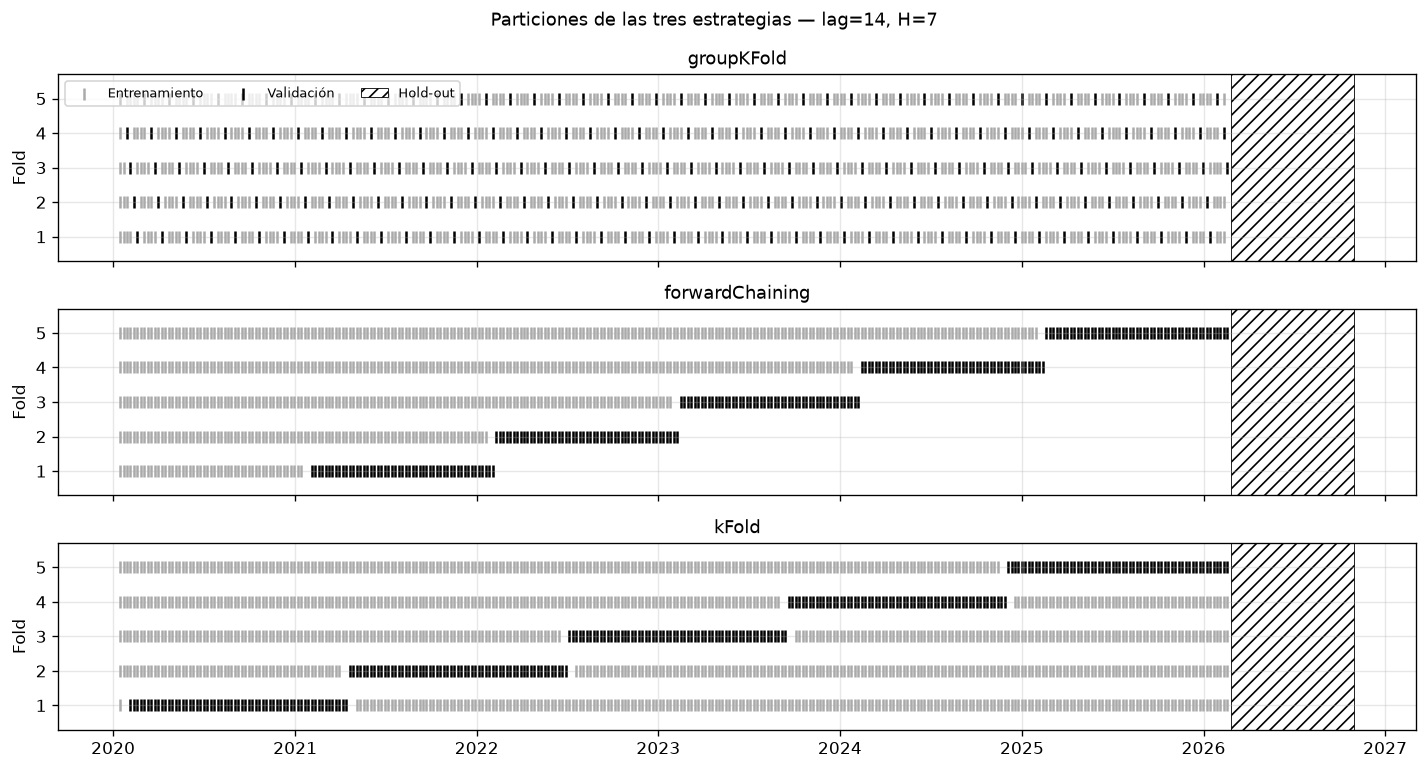

In [4]:
LAG_ESQ, H_ESQ = 14, 7
fig, axes = plt.subplots(3, 1, figsize=(12, 6.5), sharex=True)
for ax, estrategia in zip(axes, SPLIT_FUNCTIONS):
    for fold, (it, iyt, iv, iyv) in enumerate(particiones(estrategia, len(serie_cv), LAG_ESQ, H_ESQ), 1):
        ax.scatter(fechas_cv[iyt[:, 0]], np.full(len(iyt), fold), marker='|', s=60, color='#aaaaaa',
                   label='Entrenamiento' if fold == 1 else None)
        ax.scatter(fechas_cv[iyv[:, 0]], np.full(len(iyv), fold), marker='|', s=60, color='black',
                   label='Validación' if fold == 1 else None)
    ax.axvspan(fechas_ho[0], fechas_ho[-1], facecolor='white', edgecolor='black', hatch='///', lw=0.5,
               label='Hold-out')
    ax.set_title(estrategia)
    ax.set_ylabel('Fold')
    ax.set_yticks(range(1, K_FOLDS + 1))
    ax.set_ylim(0.3, K_FOLDS + 0.7)
axes[0].legend(loc='upper left', fontsize=8, ncol=3)
plt.suptitle(f'Particiones de las tres estrategias — lag={LAG_ESQ}, H={H_ESQ}', fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, 'train_esquema_particiones.png'), dpi=150, bbox_inches='tight')
plt.show()

**Interpretación.** La figura muestra cómo particiona cada estrategia para lag = 14 y H = 7. En Forward Chaining el entrenamiento siempre antecede a la validación y crece fold a fold, de unas 51 ventanas en el fold 1 a unas 260 en el fold 5 (promedio de las 16 combinaciones), mientras cada bloque de validación cubre cerca de un año, entre el 27 de enero de 2021 y el 24 de febrero de 2026. K-Fold valida en cinco bloques contiguos de unas 63 ventanas y entrena con las ventanas anteriores y posteriores a cada bloque. Group K-Fold reparte la validación a lo largo de toda la serie, una de cada cinco ventanas. El hold-out, desde el 25 de febrero de 2026, queda fuera de las tres.

Esto quiere decir que solo Forward Chaining reproduce la situación de uso real, en la que el modelo se entrena con el pasado y pronostica el futuro inmediato. K-Fold entrena con información posterior a la validación, aunque la purga impide que compartan días objetivo. En Group K-Fold, en cambio, una parte de los días objetivo de validación también es objetivo en el entrenamiento, porque las ventanas vecinas se solapan; el cuaderno 4 (sección 9) cuantifica ese solapamiento.

Por tal motivo, se adopta Forward Chaining como estrategia de referencia para elegir el modelo final, y las otras dos se conservan para la comparación que exige el enunciado, como contraste de qué tan optimistas resultan sus métricas.

## 5. Entrenamiento con las tres estrategias de CV

Para cada estrategia, combinación (lag × horizonte) y fold se ajustan los escaladores solo con el entrenamiento, se entrena el MLP de Keras con la arquitectura elegida en el cuaderno 2 y el `MLPRegressor` de referencia, y se calculan las métricas en validación. Se guardan las métricas por fold y por paso de horizonte, y las predicciones del primer paso ($h = 1$) en entrenamiento y validación, con su fecha. El avance queda en `results/progreso_entrenamiento.log`.

In [5]:
fold_rows, h_rows, pred_frames = [], [], []
configs = [(e, lag, H) for e in SPLIT_FUNCTIONS for lag in LAGS_LIST for H in HORIZONS_LIST]

if os.path.exists(LOG_PATH):
    os.remove(LOG_PATH)
registrar(f'Inicio: {len(configs)} combinaciones estrategia × lag × horizonte, {K_FOLDS} folds cada una')
t0 = time.time()

for n_cfg, (estrategia, lag, H) in enumerate(configs, 1):
    arch, dmask = get_best_arch(lag, H)
    for fold, (it, iyt, iv, iyv) in enumerate(particiones(estrategia, len(serie_cv), lag, H), 1):
        Xt, yt, Xv, yv = serie_cv[it], serie_cv[iyt], serie_cv[iv], serie_cv[iyv]
        sx = StandardScaler().fit(Xt)
        sy = StandardScaler().fit(yt)
        Xt_s, yt_s = sx.transform(Xt), sy.transform(yt)
        Xv_s, yv_s = sx.transform(Xv), sy.transform(yv)

        baseline = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=300, random_state=42).fit(Xt_s, yt_s)
        yhat_base = sy.inverse_transform(baseline.predict(Xv_s).reshape(len(Xv_s), -1))

        tf.keras.backend.clear_session()
        model = construir_modelo(arch, dmask, lag, H)
        hist = model.fit(Xt_s, yt_s, validation_data=(Xv_s, yv_s), epochs=EPOCHS_FINAL,
                         batch_size=BATCH_SIZE, shuffle=False, verbose=0,
                         callbacks=callbacks_entrenamiento())
        yhat_t = sy.inverse_transform(model(Xt_s, training=False).numpy())
        yhat_v = sy.inverse_transform(model(Xv_s, training=False).numpy())

        met = calcular_metricas(yv, yhat_v)
        clave = {'estrategia': estrategia, 'lag': lag, 'horizonte': H, 'fold': fold}
        for h in range(H):
            h_rows.append({**clave, 'h': h + 1, 'mape': met['mape_h'][h], 'mae': met['mae_h'][h],
                           'rmse': met['rmse_h'][h], 'mse': met['mse_h'][h]})
        fold_rows.append({
            **clave,
            'n_train': len(Xt), 'n_val': len(Xv),
            'val_desde': pd.Timestamp(fechas_cv[iyv.min()]).date(),
            'val_hasta': pd.Timestamp(fechas_cv[iyv.max()]).date(),
            'mape': np.mean(met['mape_h']), 'mae': np.mean(met['mae_h']),
            'rmse': np.mean(met['rmse_h']), 'mse': np.mean(met['mse_h']),
            'bds_pvalue_h1': bds_pvalue(yv[:, 0] - yhat_v[:, 0]),
            'rmse_baseline': float(np.sqrt(np.mean((yv - yhat_base) ** 2))),
            'mejor_epoca': int(np.argmin(hist.history['val_loss']) + 1),
            'epocas': len(hist.history['val_loss']),
        })
        for conjunto, iy, yr, yp in [('train', iyt, yt, yhat_t), ('val', iyv, yv, yhat_v)]:
            pred_frames.append(pd.DataFrame({**clave, 'conjunto': conjunto, 'fecha': fechas_cv[iy[:, 0]],
                                             'real': yr[:, 0], 'pred': yp[:, 0]}))
        del model, baseline
    gc.collect()
    transcurrido = time.time() - t0
    faltan = transcurrido / n_cfg * (len(configs) - n_cfg)
    registrar(f'{estrategia} lag={lag} H={H} ({n_cfg}/{len(configs)}) | {transcurrido / 60:.1f} min | faltan ~{faltan / 60:.1f} min')

fold_df  = pd.DataFrame(fold_rows)
h_df     = pd.DataFrame(h_rows)
preds_df = pd.concat(pred_frames, ignore_index=True)
fold_df.to_csv(os.path.join(RESULTS_DIR, 'cv_metricas_por_fold.csv'), index=False)
h_df.to_csv(os.path.join(RESULTS_DIR, 'cv_metricas_por_h.csv'), index=False)
preds_df.to_csv(os.path.join(RESULTS_DIR, 'predicciones_h1.csv'), index=False)
registrar('Validación cruzada terminada: cv_metricas_por_fold.csv, cv_metricas_por_h.csv y predicciones_h1.csv guardados')

[18:56:21] Inicio: 48 combinaciones estrategia × lag × horizonte, 5 folds cada una


[18:57:02] groupKFold lag=7 H=7 (1/48) | 0.7 min | faltan ~31.8 min


[18:57:32] groupKFold lag=7 H=14 (2/48) | 1.2 min | faltan ~27.2 min


[18:58:11] groupKFold lag=7 H=21 (3/48) | 1.8 min | faltan ~27.5 min


[18:58:55] groupKFold lag=7 H=28 (4/48) | 2.6 min | faltan ~28.2 min


[18:59:31] groupKFold lag=14 H=7 (5/48) | 3.2 min | faltan ~27.2 min


... (40 outputs left out)

[19:29:04] kFold lag=28 H=14 (46/48) | 32.7 min | faltan ~1.4 min


[19:29:55] kFold lag=28 H=21 (47/48) | 33.6 min | faltan ~0.7 min


[19:30:45] kFold lag=28 H=28 (48/48) | 34.4 min | faltan ~0.0 min


[19:30:45] Validación cruzada terminada: cv_metricas_por_fold.csv, cv_metricas_por_h.csv y predicciones_h1.csv guardados


## 6. Métricas por fold en validación, para cada lag × horizonte

Las 16 tablas corresponden a Forward Chaining, la estrategia elegida (sección 7). Cada fila es un fold; las métricas son el promedio sobre los pasos $h = 1, …, H$, y `bds_pvalue_h1` es el p-valor de la prueba BDS sobre los residuos de $h = 1$. `rmse_baseline` es el RMSE del `MLPRegressor` de referencia en el mismo fold. Las tablas de las otras dos estrategias, y el detalle por paso de horizonte, están en `results/cv_metricas_por_fold.csv` y `results/cv_metricas_por_h.csv`.

In [6]:
COLS_METRICAS = ['n_train', 'n_val', 'mape', 'mae', 'rmse', 'mse', 'bds_pvalue_h1', 'rmse_baseline']


def tabla_folds(estrategia, lag, H):
    sub = fold_df[(fold_df.estrategia == estrategia) & (fold_df.lag == lag) & (fold_df.horizonte == H)]
    t = sub.set_index('fold')[COLS_METRICAS].astype(float)
    media, std = t.mean(), t.std()
    t.index = [f'Fold {i}' for i in t.index]
    t.loc['Media'] = media
    t.loc['Std'] = std
    return t.round(4)


for lag in LAGS_LIST:
    for H in HORIZONS_LIST:
        print(f'=== Validación · forwardChaining · lag={lag} · H={H} ===')
        display(tabla_folds('forwardChaining', lag, H))

=== Validación · forwardChaining · lag=7 · H=7 ===


,n_train,n_val,mape,mae,rmse,mse,bds_pvalue_h1,rmse_baseline
Fold 1,54.0000,53.0,24.9217,0.4841,0.5873,0.3515,0.7227,0.7863
Fold 2,107.0000,53.0,21.4560,0.4416,0.5489,0.3027,0.2718,0.6581
Fold 3,160.0000,53.0,23.7663,0.4297,0.5380,0.2909,0.2287,0.6369
Fold 4,213.0000,53.0,22.3868,0.4362,0.5360,0.2912,0.5413,0.6020
Fold 5,266.0000,53.0,20.4767,0.4382,0.5521,0.3098,0.4487,0.6098
Media,160.0000,53.0,22.6015,0.4459,0.5525,0.3092,0.4426,0.6586
Std,83.8004,0.0,1.7758,0.0217,0.0207,0.0250,0.2020,0.0748


=== Validación · forwardChaining · lag=7 · H=14 ===


,n_train,n_val,mape,mae,rmse,mse,bds_pvalue_h1,rmse_baseline
Fold 1,52.0000,53.0,25.6960,0.4919,0.5933,0.3572,0.8580,0.7605
Fold 2,105.0000,53.0,21.5070,0.4437,0.5531,0.3076,0.1847,0.6315
Fold 3,158.0000,53.0,24.6276,0.4418,0.5477,0.3018,0.2244,0.6166
Fold 4,211.0000,53.0,22.4002,0.4352,0.5347,0.2897,0.5177,0.5694
Fold 5,264.0000,53.0,21.4380,0.4618,0.5814,0.3421,0.4800,0.6186
Media,158.0000,53.0,23.1338,0.4549,0.5621,0.3197,0.4530,0.6393
Std,83.8004,0.0,1.9272,0.0229,0.0244,0.0286,0.2707,0.0717


=== Validación · forwardChaining · lag=7 · H=21 ===


,n_train,n_val,mape,mae,rmse,mse,bds_pvalue_h1,rmse_baseline
Fold 1,51.0000,53.0000,26.4201,0.4997,0.5986,0.3624,0.6028,0.7479
Fold 2,104.0000,53.0000,21.4837,0.4455,0.5558,0.3101,0.8549,0.6336
Fold 3,157.0000,52.0000,24.9530,0.4453,0.5499,0.3040,0.3696,0.6052
Fold 4,209.0000,53.0000,22.6127,0.4385,0.5359,0.2906,0.0137,0.5524
Fold 5,262.0000,53.0000,21.5833,0.4676,0.5880,0.3481,0.4111,0.6161
Media,156.6000,52.8000,23.4105,0.4593,0.5656,0.3231,0.4504,0.6310
Std,83.3265,0.4472,2.1866,0.0251,0.0265,0.0307,0.3105,0.0720


... (22 outputs left out)

=== Validación · forwardChaining · lag=28 · H=21 ===


,n_train,n_val,mape,mae,rmse,mse,bds_pvalue_h1,rmse_baseline
Fold 1,50.0000,52.0000,25.4521,0.4931,0.5984,0.3626,0.7407,0.7554
Fold 2,102.0000,52.0000,21.6857,0.4454,0.5495,0.3032,0.5757,0.6964
Fold 3,154.0000,51.0000,23.5796,0.4289,0.5356,0.2883,0.5361,0.6698
Fold 4,205.0000,52.0000,22.4523,0.4364,0.5376,0.2928,0.9448,0.5773
Fold 5,257.0000,52.0000,22.1027,0.4753,0.5955,0.3561,0.1640,0.7092
Media,153.6000,51.8000,23.0545,0.4558,0.5633,0.3206,0.5922,0.6816
Std,81.7453,0.4472,1.5138,0.0273,0.0312,0.0359,0.2886,0.0660


=== Validación · forwardChaining · lag=28 · H=28 ===


,n_train,n_val,mape,mae,rmse,mse,bds_pvalue_h1,rmse_baseline
Fold 1,49.0000,52.0000,25.7761,0.4962,0.5999,0.3638,0.9025,0.7748
Fold 2,101.0000,51.0000,21.8150,0.4478,0.5507,0.3048,0.7127,0.7270
Fold 3,152.0000,52.0000,23.9073,0.4309,0.5381,0.2911,0.5640,0.6329
Fold 4,204.0000,51.0000,22.6004,0.4395,0.5407,0.2959,0.1041,0.5780
Fold 5,255.0000,52.0000,21.8433,0.4744,0.5987,0.3601,0.6739,0.7011
Media,152.2000,51.6000,23.1884,0.4578,0.5656,0.3232,0.5914,0.6828
Std,81.4291,0.5477,1.6774,0.0270,0.0311,0.0358,0.2985,0.0778


**Interpretación.** En Forward Chaining el RMSE de validación por fold, promediado sobre las 16 combinaciones, va de 0,535 a 0,599 m/s, y el patrón se repite en casi todas las tablas: el fold 1 (2021–2022), entrenado con unas 51 ventanas, es el peor (0,599 m/s); los folds 2 a 4 bajan a 0,535–0,550 m/s, y el fold 5 (2025–2026) vuelve a subir (0,582 m/s). La desviación estándar del RMSE entre folds es de 0,028 m/s en promedio, el MAPE ronda el 23 %, la prueba BDS no rechaza la independencia en 76 de los 80 folds y el MLP mejora al `MLPRegressor` de referencia en un 16,7 % de RMSE.

Lo anterior indica que la variación entre periodos pesa más que la elección del lag o del horizonte: la diferencia entre la mejor y la peor combinación en la tabla consolidada (0,014 m/s) es menor que la dispersión entre folds. El fold 1 refleja el costo de entrenar con poca historia, y el fold 5 sugiere que 2025–2026 fue un periodo más difícil de pronosticar, lo que anticipa un error algo mayor en el hold-out, que es su continuación inmediata. Hay que tener en cuenta, además, que en validación las ventanas de un fold están separadas por 7 días, de modo que la BDS evalúa aquí la dependencia entre residuos semanales.

Por ello, se recomienda leer las diferencias pequeñas entre configuraciones junto con su desviación estándar entre folds, y no como mejoras reales, y dejar el diagnóstico de la dependencia diaria para los residuos del hold-out (cuaderno 4).

## 7. Tabla comparativa por estrategia de validación

In [7]:
comp = (fold_df.groupby(['estrategia', 'lag', 'horizonte'])
        [['rmse', 'mape', 'mae', 'mse', 'bds_pvalue_h1', 'rmse_baseline']]
        .mean().reset_index())
comp.to_csv(os.path.join(RESULTS_DIR, 'cv_comparativa_estrategias.csv'), index=False)
print('=== Validación: promedio sobre folds por estrategia, lag y horizonte ===')
display(comp.rename(columns={'horizonte': 'horizonte H', 'rmse': 'RMSE', 'mape': 'MAPE', 'mae': 'MAE',
                             'mse': 'MSE', 'bds_pvalue_h1': 'BDS_pvalue_h1',
                             'rmse_baseline': 'RMSE baseline'}).round(4))

resumen = fold_df.assign(residuos_iid=fold_df.bds_pvalue_h1 > 0.05).groupby('estrategia').agg(
    RMSE=('rmse', 'mean'), MAPE=('mape', 'mean'), RMSE_baseline=('rmse_baseline', 'mean'),
    BDS_pvalue_h1=('bds_pvalue_h1', 'mean'), folds_iid=('residuos_iid', 'mean'))
print('=== Validación: resumen por estrategia (promedio de las 16 combinaciones lag × H) ===')
display(resumen.round(4))

=== Validación: promedio sobre folds por estrategia, lag y horizonte ===

,estrategia,lag,horizonte H,RMSE,MAPE,MAE,MSE,BDS_pvalue_h1,RMSE baseline
0,forwardChaining,7,7,0.5525,22.6015,0.4459,0.3092,0.4426,0.6586
1,forwardChaining,7,14,0.5621,23.1338,0.4549,0.3197,0.4530,0.6393
2,forwardChaining,7,21,0.5656,23.4105,0.4593,0.3231,0.4504,0.6310
3,forwardChaining,7,28,0.5664,23.3742,0.4590,0.3239,0.5554,0.6308
4,forwardChaining,14,7,0.5543,22.7950,0.4490,0.3113,0.4512,0.6916
5,forwardChaining,14,14,0.5635,23.2059,0.4570,0.3212,0.6939,0.6956
6,forwardChaining,14,21,0.5656,23.2840,0.4587,0.3233,0.4864,0.6774
7,forwardChaining,14,28,0.5662,23.3412,0.4591,0.3236,0.4300,0.6652
8,forwardChaining,21,7,0.5524,22.8107,0.4485,0.3090,0.8643,0.6899
9,forwardChaining,21,14,0.5608,23.1240,0.4551,0.3177,0.6413,0.6872


=== Validación: resumen por estrategia (promedio de las 16 combinaciones lag × H) ===


,RMSE,MAPE,RMSE_baseline,BDS_pvalue_h1,folds_iid
estrategia,,,,,
forwardChaining,0.5614,23.0691,0.6739,0.5574,0.95
groupKFold,0.5668,22.9108,0.6876,0.4141,0.85
kFold,0.5688,22.8457,0.6607,0.4590,0.90


**Interpretación.** En promedio sobre las 16 combinaciones, Forward Chaining obtiene el menor RMSE de validación (0,5614 m/s), seguido de Group K-Fold (0,5668 m/s) y K-Fold (0,5688 m/s), y ese orden se mantiene en los cuatro horizontes. El MAPE va en sentido contrario, aunque con diferencias mínimas (23,07 %, 22,91 % y 22,85 %). En los residuos, el p-valor medio de la prueba BDS es mayor en Forward Chaining (0,557) que en K-Fold (0,459) y en Group K-Fold (0,414), y esta última rechaza la independencia en 12 de 80 folds, frente a 8 de K-Fold y 4 de Forward Chaining.

Esto significa que, en este problema, el sesgo optimista que se espera de Group K-Fold y de K-Fold no aparece en el error: las tres estrategias difieren en menos de 0,008 m/s, una cantidad menor que la variación entre folds (desviación de 0,025 a 0,035 m/s), así que con cinco folds no son distinguibles. La explicación más probable es que el MLP predice cerca del nivel medio (sección 10.1), de modo que entrenar con ventanas vecinas o futuras le aporta poca información explotable: la fuga existe en Group K-Fold, pero un modelo de señal débil no la aprovecha.

Por tanto, corresponde elegir la estrategia por su validez y no por su error. Forward Chaining es la única que entrena siempre con el pasado y valida con el futuro inmediato, como ocurre en producción (Bergmeir & Benítez, 2012), y además obtuvo el menor RMSE y los residuos más cercanos a la independencia. Por eso se usa para elegir el lag y el número de épocas del modelo final.

## 8. Visualizaciones

### 8.1 RMSE promedio vs. horizonte de predicción, por lag y estrategia

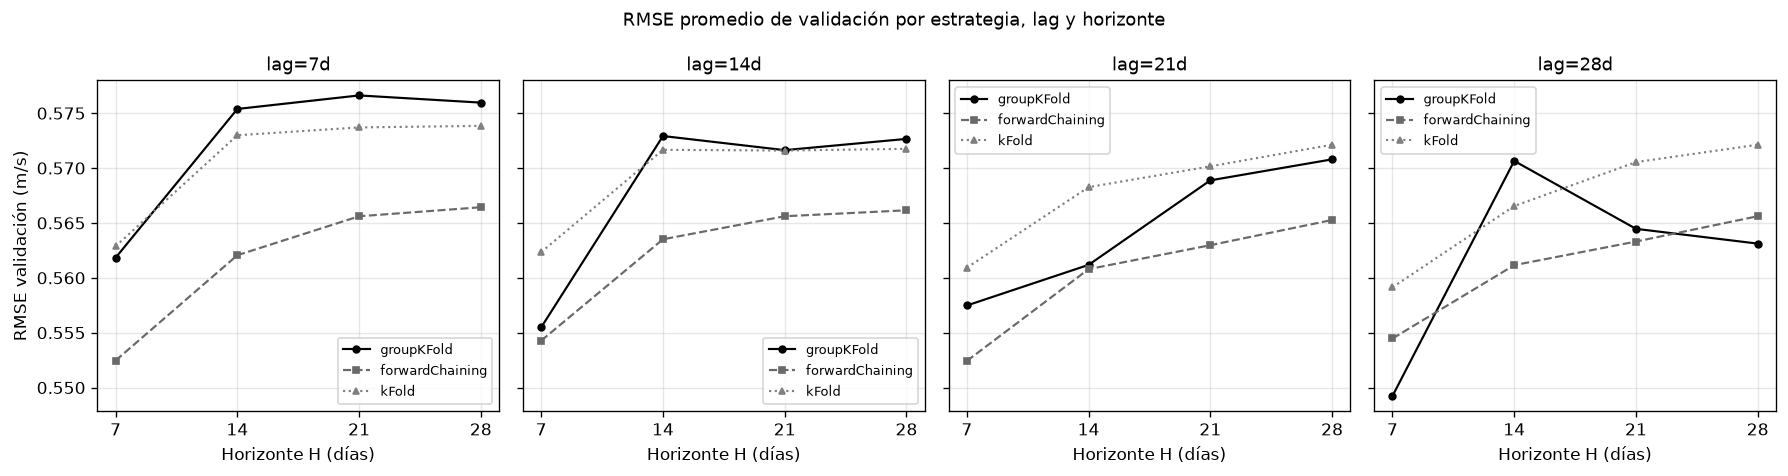

In [8]:
fig, axes = plt.subplots(1, len(LAGS_LIST), figsize=(15, 4), sharey=True)
estilos = {'groupKFold': ('-', 'o', 'black'), 'forwardChaining': ('--', 's', 'dimgray'),
           'kFold': (':', '^', 'gray')}
for col, lag in enumerate(LAGS_LIST):
    ax = axes[col]
    for estrategia, (ls, mk, c) in estilos.items():
        sub = comp[(comp.estrategia == estrategia) & (comp.lag == lag)].sort_values('horizonte')
        ax.plot(sub['horizonte'], sub['rmse'], ls=ls, marker=mk, color=c, lw=1.3, ms=4, label=estrategia)
    ax.set_title(f'lag={lag}d')
    ax.set_xlabel('Horizonte H (días)')
    ax.set_xticks(HORIZONS_LIST)
    if col == 0:
        ax.set_ylabel('RMSE validación (m/s)')
    ax.legend(fontsize=8)
plt.suptitle('RMSE promedio de validación por estrategia, lag y horizonte', fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, 'train_rmse_vs_horizonte.png'), dpi=150)
plt.show()

**Interpretación.** En las tres estrategias y en los cuatro lags el RMSE de validación sube con el horizonte, pero poco: en Forward Chaining pasa de 0,5534 m/s con H = 7 a 0,5659 m/s con H = 28, un aumento del 2,3 %, y la mayor parte ocurre entre H = 7 y H = 14. Las curvas de los cuatro lags casi se superponen: con H fijo, la diferencia entre el mejor y el peor lag no pasa de 0,003 m/s.

Esto quiere decir que agregar historia más allá de 7 días no le aporta información útil al MLP y que el error se estabiliza pronto con el horizonte. Sin embargo, una degradación tan suave no significa que el modelo pronostique bien a 28 días, sino que desde los primeros pasos ya predice cerca del nivel medio, cuyo error no depende de la distancia (sección 8.2).

Así las cosas, se decide elegir el lag del modelo final por el menor RMSE de Forward Chaining en cada horizonte, sabiendo que la elección entre lags es prácticamente indiferente, y no buscar mejoras ampliando la ventana de entrada.

### 8.2 RMSE por fold y RMSE por paso de horizonte

La primera cuadrícula muestra el RMSE de validación de cada fold para las tres estrategias, en las 16 combinaciones (filas: lag; columnas: horizonte). La segunda muestra, para Forward Chaining, el RMSE medio sobre folds en cada paso $h = 1, …, H$.

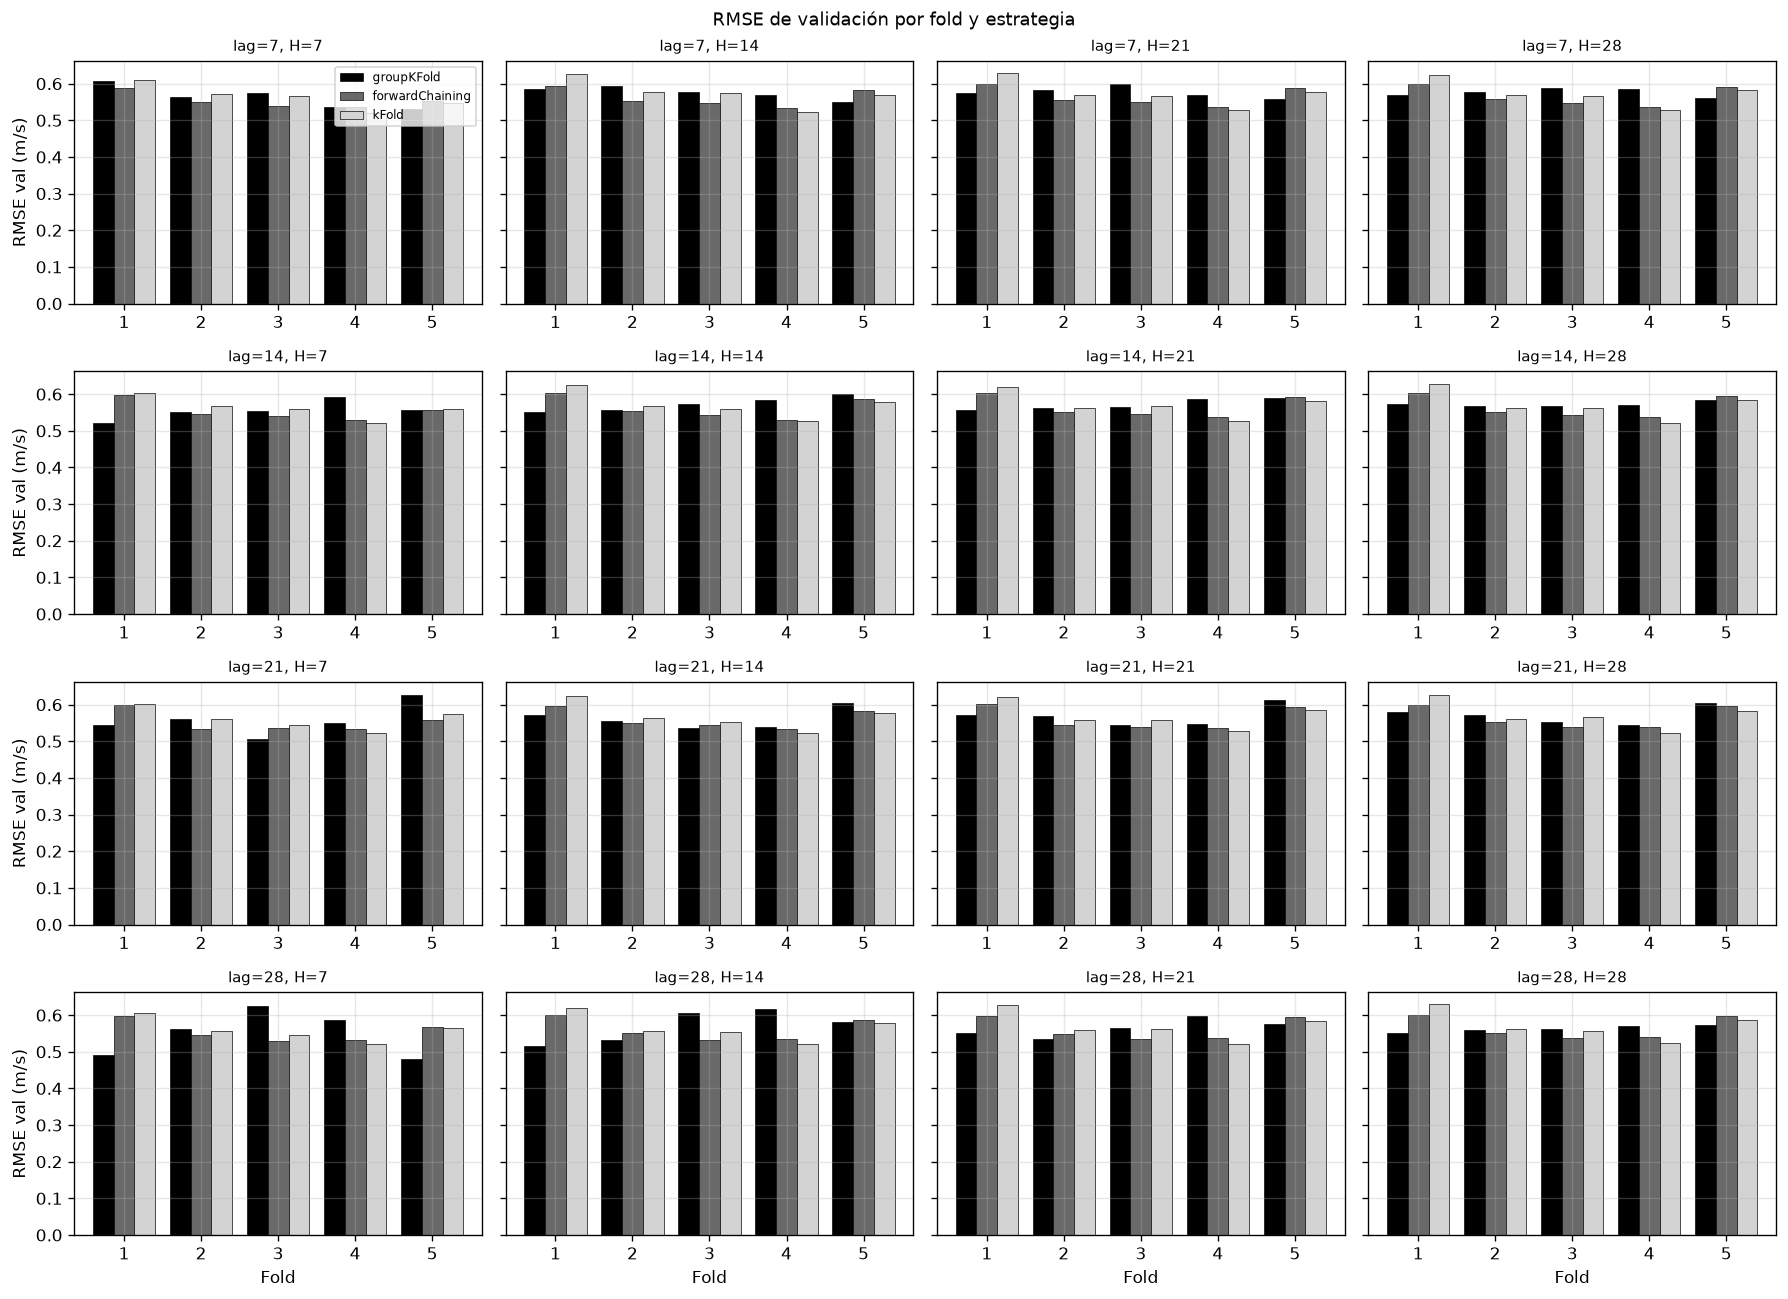

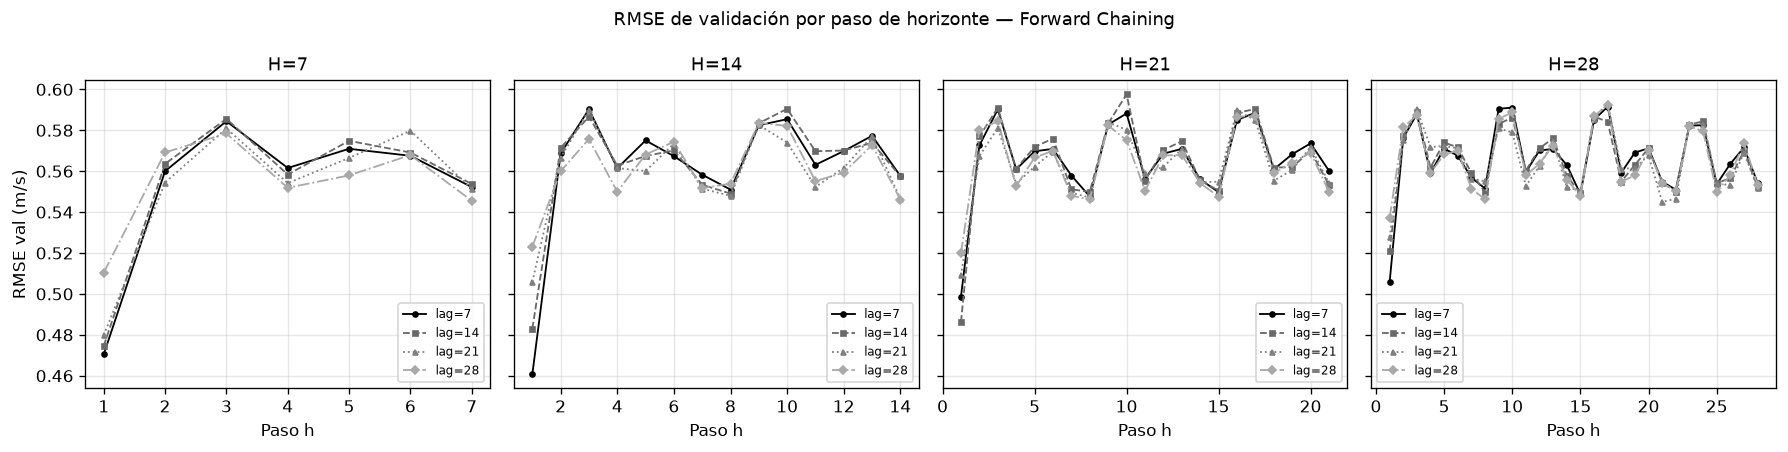

In [9]:
colores = {'groupKFold': 'black', 'forwardChaining': 'dimgray', 'kFold': 'lightgray'}
fig, axes = plt.subplots(len(LAGS_LIST), len(HORIZONS_LIST), figsize=(15, 11), sharey=True)
ancho = 0.27
for r, lag in enumerate(LAGS_LIST):
    for c, H in enumerate(HORIZONS_LIST):
        ax = axes[r, c]
        for i, (estrategia, color) in enumerate(colores.items()):
            sub = fold_df[(fold_df.estrategia == estrategia) & (fold_df.lag == lag) & (fold_df.horizonte == H)]
            ax.bar(sub['fold'] + (i - 1) * ancho, sub['rmse'], width=ancho, color=color,
                   edgecolor='black', lw=0.4, label=estrategia)
        ax.set_title(f'lag={lag}, H={H}', fontsize=9)
        ax.set_xticks(range(1, K_FOLDS + 1))
        if c == 0:
            ax.set_ylabel('RMSE val (m/s)')
        if r == len(LAGS_LIST) - 1:
            ax.set_xlabel('Fold')
axes[0, 0].legend(fontsize=7)
plt.suptitle('RMSE de validación por fold y estrategia', fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, 'train_rmse_por_fold.png'), dpi=150)
plt.show()

fig, axes = plt.subplots(1, len(HORIZONS_LIST), figsize=(15, 3.8), sharey=True)
for c, H in enumerate(HORIZONS_LIST):
    ax = axes[c]
    for i, lag in enumerate(LAGS_LIST):
        sub = (h_df[(h_df.estrategia == 'forwardChaining') & (h_df.lag == lag) & (h_df.horizonte == H)]
               .groupby('h')['rmse'].mean())
        ax.plot(sub.index, sub.values, ls=['-', '--', ':', '-.'][i], marker=['o', 's', '^', 'D'][i], ms=3,
                color=['black', 'dimgray', 'gray', 'darkgray'][i], lw=1.1, label=f'lag={lag}')
    ax.set_title(f'H={H}')
    ax.set_xlabel('Paso h')
    if c == 0:
        ax.set_ylabel('RMSE val (m/s)')
    ax.legend(fontsize=7)
plt.suptitle('RMSE de validación por paso de horizonte — Forward Chaining', fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, 'train_rmse_por_paso_h.png'), dpi=150)
plt.show()

**Interpretación.** La primera cuadrícula confirma que la variación entre folds domina sobre la variación entre estrategias: en las 16 combinaciones, las barras de un mismo fold tienen alturas parecidas en las tres estrategias, mientras el RMSE cambia más de un fold a otro. La segunda cuadrícula muestra dónde está la información: en Forward Chaining el RMSE del primer paso ($h = 1$) es de 0,484 m/s con H = 7 y de 0,523 m/s con H = 28; luego sube durante los primeros pasos y se estabiliza alrededor de 0,55 m/s desde $h \approx 5$, por debajo de la desviación estándar de la serie en 2020–2026 (0,581 m/s).

Es decir, el MLP aprovecha la persistencia de corto plazo del viento en los primeros días, y a partir de una semana su error converge al de un pronóstico que solo conoce el nivel medio. Que el error de $h = 1$ sea menor con H = 7 que con H = 28 indica, además, que la salida multisalida reparte la capacidad de la red entre todos los pasos: con un horizonte más largo, el primer paso se predice peor.

Por esta razón, lo indicado es reportar el desempeño por paso de horizonte y no solo el promedio y, si el interés operativo está en los primeros días, preferir horizontes cortos o ponderar más los primeros pasos en la función de pérdida.

## 9. Tabla consolidada lag × horizonte

RMSE y MAPE promedio de validación (Forward Chaining) para las 16 configuraciones.

In [10]:
fc_sum = comp[comp.estrategia == 'forwardChaining']
pivot_rmse = fc_sum.pivot_table(index='lag', columns='horizonte', values='rmse').round(4)
pivot_mape = fc_sum.pivot_table(index='lag', columns='horizonte', values='mape').round(4)
print('=== Validación: RMSE promedio (forwardChaining) — lag × horizonte ===')
display(pivot_rmse)
print('=== Validación: MAPE promedio (forwardChaining) — lag × horizonte ===')
display(pivot_mape)

=== Validación: RMSE promedio (forwardChaining) — lag × horizonte ===


horizonte,7,14,21,28
lag,,,,
7,0.5525,0.5621,0.5656,0.5664
14,0.5543,0.5635,0.5656,0.5662
21,0.5524,0.5608,0.5630,0.5653
28,0.5545,0.5612,0.5633,0.5656


=== Validación: MAPE promedio (forwardChaining) — lag × horizonte ===


horizonte,7,14,21,28
lag,,,,
7,22.6015,23.1338,23.4105,23.3742
14,22.7950,23.2059,23.2840,23.3412
21,22.8107,23.1240,23.1285,23.1424
28,22.5154,22.9957,23.0545,23.1884


**Interpretación.** La tabla consolidada de Forward Chaining tiene un rango muy estrecho: el RMSE de validación va de 0,5524 m/s (lag = 21, H = 7) a 0,5664 m/s (lag = 7, H = 28), y el MAPE de 22,5 % a 23,4 %. El gradiente con el horizonte es claro, pues entre H = 7 y H = 28 el RMSE sube de 0,011 a 0,014 m/s en cada lag, mientras el efecto del lag es casi nulo, de 0,003 m/s como máximo.

De esta forma, con esta serie y este modelo el horizonte determina el error y el tamaño de la ventana de entrada es secundario. Un MAPE cercano al 23 % en una variable con media de 2,15 m/s equivale a un error típico de alrededor de 0,5 m/s, magnitud que debe contrastarse con las referencias ingenuas del cuaderno 4 para saber cuánto aporta el modelo.

Por lo anterior, conviene elegir en cada horizonte el lag de menor RMSE, que resulta ser 21 días en los cuatro casos, y presentar la tabla con su incertidumbre entre folds para no sobreinterpretar diferencias de milésimas.

## 10. Modelo final y evaluación en el hold-out

Para cada horizonte se elige el lag con menor RMSE de validación en Forward Chaining. El modelo final usa la arquitectura de esa combinación y se reentrena con todas las ventanas de la serie previa al hold-out. Como ya no queda conjunto de validación para EarlyStopping, el número de épocas es la mediana de la mejor época observada en los folds de Forward Chaining de esa combinación. Después se evalúa una sola vez en el hold-out, con ventanas de paso 1 cuyos objetivos caen por completo en ese tramo. Los modelos y escaladores se guardan en `app/` para la API.

In [11]:
fc_folds = fold_df[fold_df.estrategia == 'forwardChaining']
holdout_rows, ho_h_rows, ho_frames = [], [], []

for H in HORIZONS_LIST:
    lag = int(fc_sum[fc_sum.horizonte == H].sort_values('rmse').iloc[0]['lag'])
    arch, dmask = get_best_arch(lag, H)
    sub = fc_folds[(fc_folds.lag == lag) & (fc_folds.horizonte == H)]
    epocas = max(int(sub['mejor_epoca'].median()), 10)

    X, y, Xcv, ycv = split_train_val_forwardChaining(
        np.arange(len(serie_cv)), numInputs=lag, numOutputs=H, numJumps=N_STEPS_JUMP)
    ult = max(X)
    Xt = serie_cv[np.vstack([X[ult], Xcv[ult]])]
    yt = serie_cv[np.vstack([y[ult], ycv[ult]])]
    sx, sy = StandardScaler().fit(Xt), StandardScaler().fit(yt)

    tf.keras.backend.clear_session()
    model_final = construir_modelo(arch, dmask, lag, H)
    model_final.fit(sx.transform(Xt), sy.transform(yt), epochs=epocas,
                    batch_size=BATCH_SIZE, shuffle=False, verbose=0)

    X_ho, y_ho = ventanas_holdout(lag, H)
    yhat_ho = sy.inverse_transform(model_final(sx.transform(X_ho), training=False).numpy())
    met = calcular_metricas(y_ho, yhat_ho)
    for h in range(H):
        ho_h_rows.append({'horizonte': H, 'lag': lag, 'h': h + 1, 'mape': met['mape_h'][h],
                          'mae': met['mae_h'][h], 'rmse': met['rmse_h'][h], 'mse': met['mse_h'][h]})
    holdout_rows.append({
        'horizonte': H, 'lag': lag, 'arquitectura': str(arch), 'dropout_mask': str(dmask),
        'epocas': epocas, 'n_train': len(Xt), 'n_holdout': len(X_ho),
        'cv_rmse_forwardChaining': float(sub['rmse'].mean()),
        'holdout_rmse': float(np.mean(met['rmse_h'])), 'holdout_mape': float(np.mean(met['mape_h'])),
        'holdout_mae': float(np.mean(met['mae_h'])), 'holdout_mse': float(np.mean(met['mse_h'])),
        'bds_pvalue_h1': bds_pvalue(y_ho[:, 0] - yhat_ho[:, 0]),
    })
    ho_frames.append(pd.DataFrame({'horizonte': H, 'lag': lag, 'fecha': fechas_ho[:len(X_ho)],
                                   'real': y_ho[:, 0], 'pred': yhat_ho[:, 0]}))

    model_final.save(os.path.join(APP_DIR, f'model_h{H}.keras'))
    joblib.dump({'x': sx, 'y': sy, 'lag': lag}, os.path.join(APP_DIR, f'scalers_h{H}.joblib'))
    registrar(f'Modelo final H={H} (lag={lag}, {epocas} épocas): RMSE hold-out={holdout_rows[-1]["holdout_rmse"]:.4f}')

ho_df = pd.DataFrame(holdout_rows)
ho_pred_df = pd.concat(ho_frames, ignore_index=True)
ho_df.to_csv(os.path.join(RESULTS_DIR, 'holdout_evaluation.csv'), index=False)
pd.DataFrame(ho_h_rows).to_csv(os.path.join(RESULTS_DIR, 'holdout_metricas_por_h.csv'), index=False)
ho_pred_df.to_csv(os.path.join(RESULTS_DIR, 'holdout_predicciones.csv'), index=False)
registrar('Fin del cuaderno 3: modelos finales y evaluación en hold-out guardados')
print('=== Hold-out: evaluación definitiva de los modelos finales (cv_rmse_forwardChaining corresponde a validación) ===')
display(ho_df.round(4))

[19:30:56] Modelo final H=7 (lag=21, 19 épocas): RMSE hold-out=0.5750


[19:31:01] Modelo final H=14 (lag=21, 18 épocas): RMSE hold-out=0.5674


[19:31:05] Modelo final H=21 (lag=21, 18 épocas): RMSE hold-out=0.5732


[19:31:08] Modelo final H=28 (lag=21, 11 épocas): RMSE hold-out=0.5728


[19:31:08] Fin del cuaderno 3: modelos finales y evaluación en hold-out guardados


=== Hold-out: evaluación definitiva de los modelos finales (cv_rmse_forwardChaining corresponde a validación) ===


,horizonte,lag,arquitectura,dropout_mask,epocas,n_train,n_holdout,cv_rmse_forwardChaining,holdout_rmse,holdout_mape,holdout_mae,holdout_mse,bds_pvalue_h1
0,7,21,"(256, 32, 256)","(False, True, True)",19,316,243,0.5524,0.5750,24.5122,0.4650,0.3316,0.0
1,14,21,"(64, 256, 128)","(False, True, True)",18,315,236,0.5608,0.5674,24.5328,0.4606,0.3221,0.0
2,21,21,"(256, 32, 256)","(False, True, True)",18,314,229,0.5630,0.5732,24.8113,0.4654,0.3287,0.0
3,28,21,"(256, 32, 256)","(False, True, True)",11,313,222,0.5653,0.5728,25.0179,0.4663,0.3282,0.0


**Interpretación.** Los modelos finales usan lag = 21 en los cuatro horizontes y se reentrenan entre 11 y 19 épocas, la mediana de la mejor época de sus folds (Prechelt, 1998). En el hold-out (25 de febrero a 31 de octubre de 2026) el RMSE va de 0,5674 a 0,5750 m/s y el MAPE de 24,5 % a 25,0 %, valores entre 1,2 % y 4,1 % mayores que el RMSE de validación de Forward Chaining (0,5524 a 0,5653 m/s). La prueba BDS sobre los residuos diarios del primer paso rechaza la independencia en los cuatro horizontes, con p-valores inferiores a 0,0001.

En ese sentido, la cercanía entre el error de validación y el del hold-out es la mejor evidencia de que el protocolo no tiene fuga de información, porque un hold-out mucho peor habría delatado una validación optimista (Tashman, 2000). El pequeño aumento es coherente con el fold 5, que ya mostraba que 2025–2026 es un periodo más difícil. Que los residuos diarios no sean independientes indica, sin embargo, que queda estructura temporal sin modelar; el cuaderno 4 la analiza.

Por tal motivo, se opta por guardar estos cuatro modelos y sus escaladores en `app/` para la API, con la advertencia de que en el hold-out su error equivale al de predecir la media (cuaderno 4, sección 9), y por documentar esa limitación en lugar de ajustar el modelo mirando el hold-out, que debe usarse una sola vez.

### 10.1 Serie temporal: entrenamiento, validación y hold-out

Para cada combinación lag × horizonte (Forward Chaining) se dibujan el mejor fold, el mediano y el peor según el RMSE de validación. Cada panel muestra, en el primer paso ($h = 1$), el valor real y el predicho en entrenamiento y en validación. En la combinación elegida para el modelo final de cada horizonte se añaden el hold-out real y el predicho.

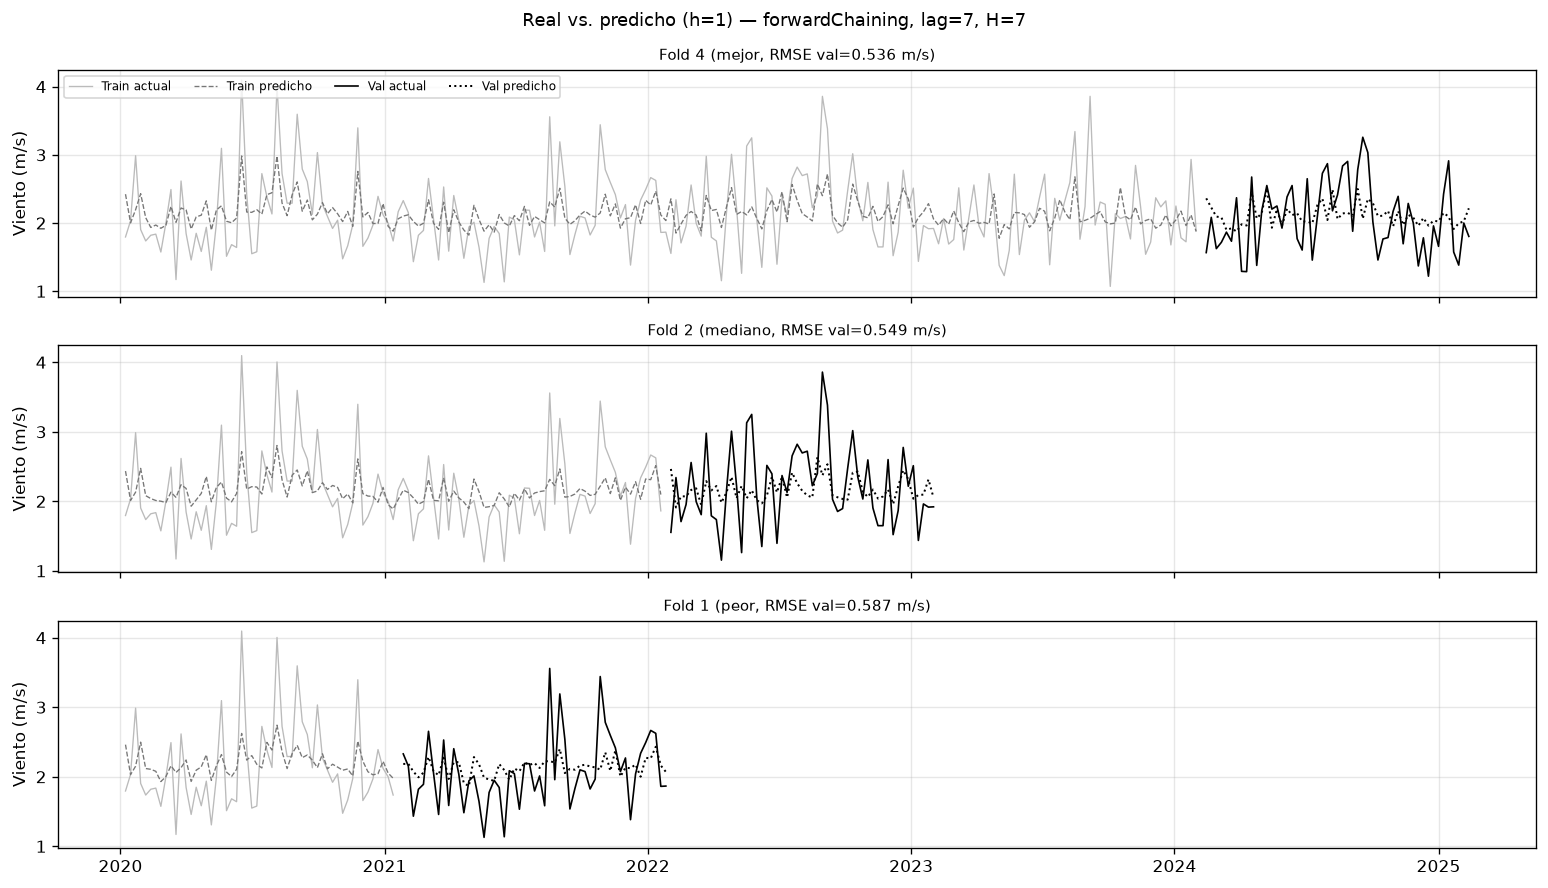

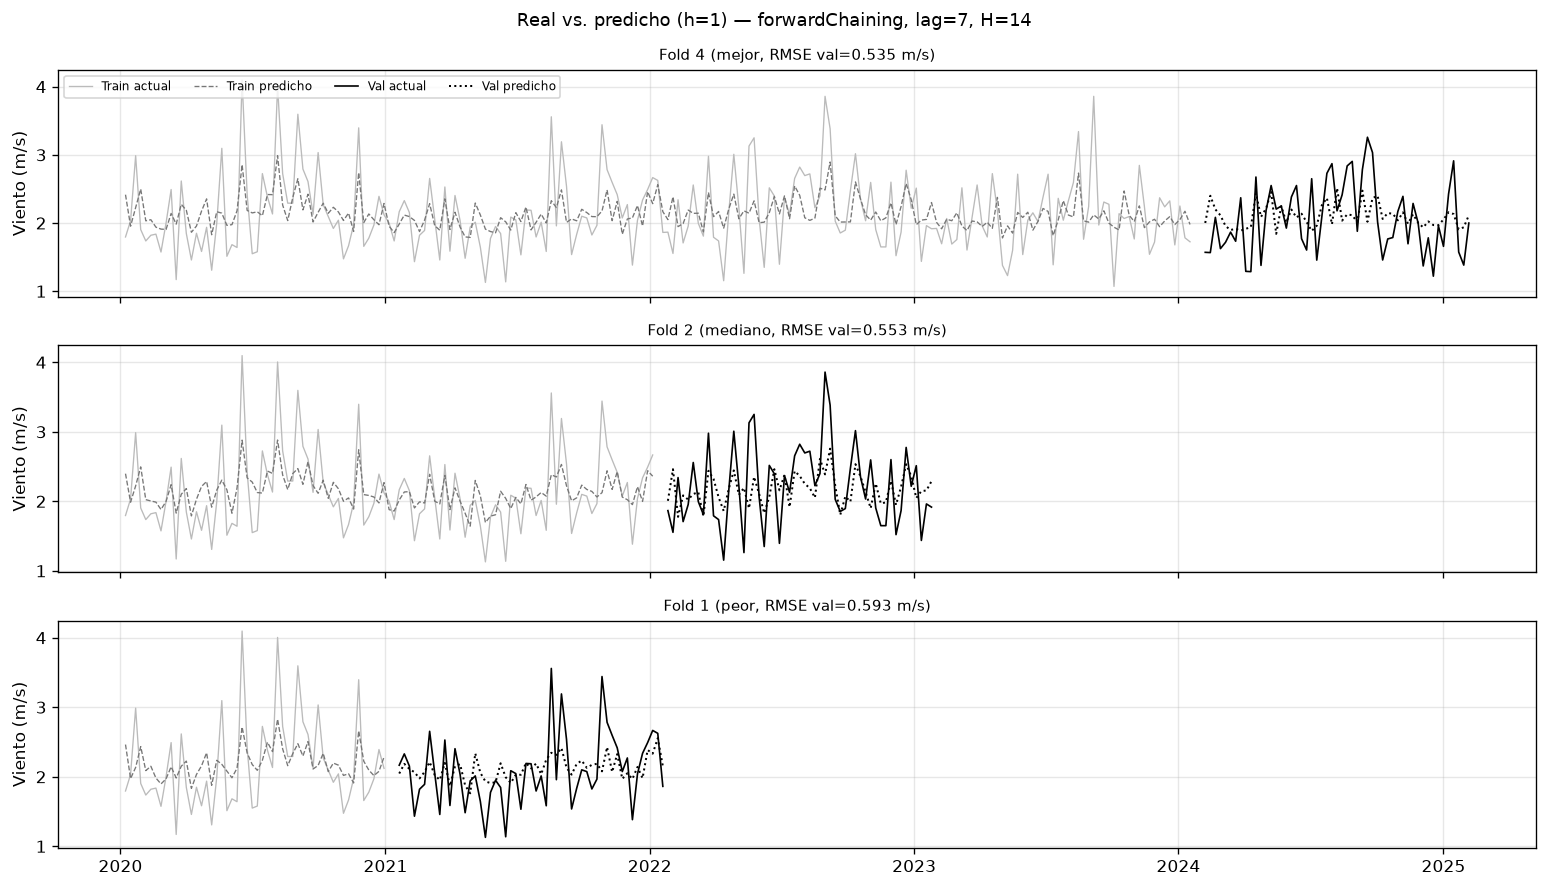

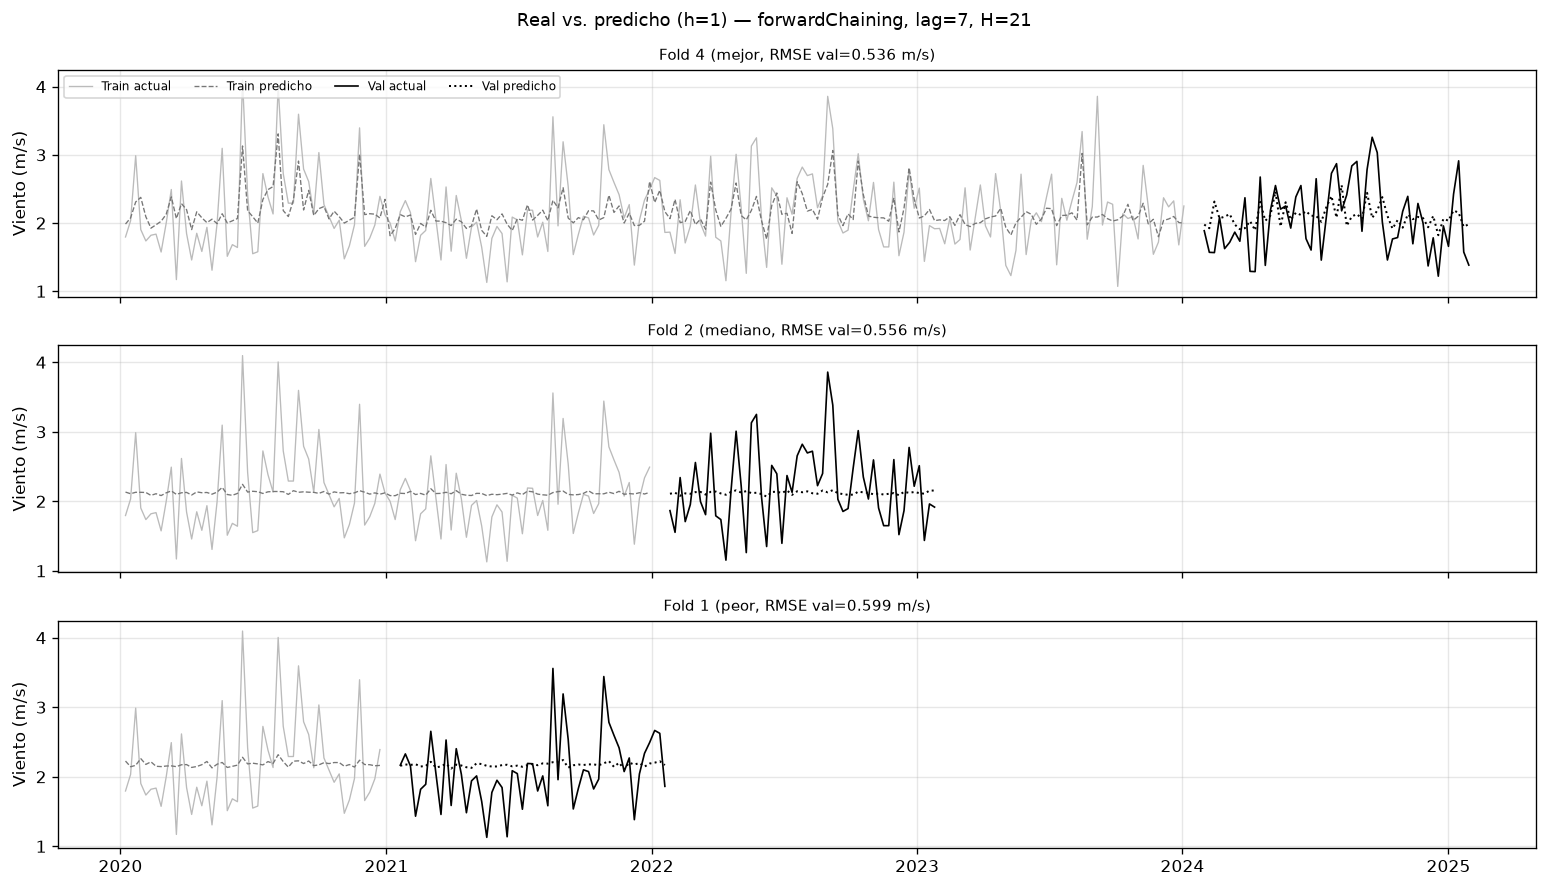

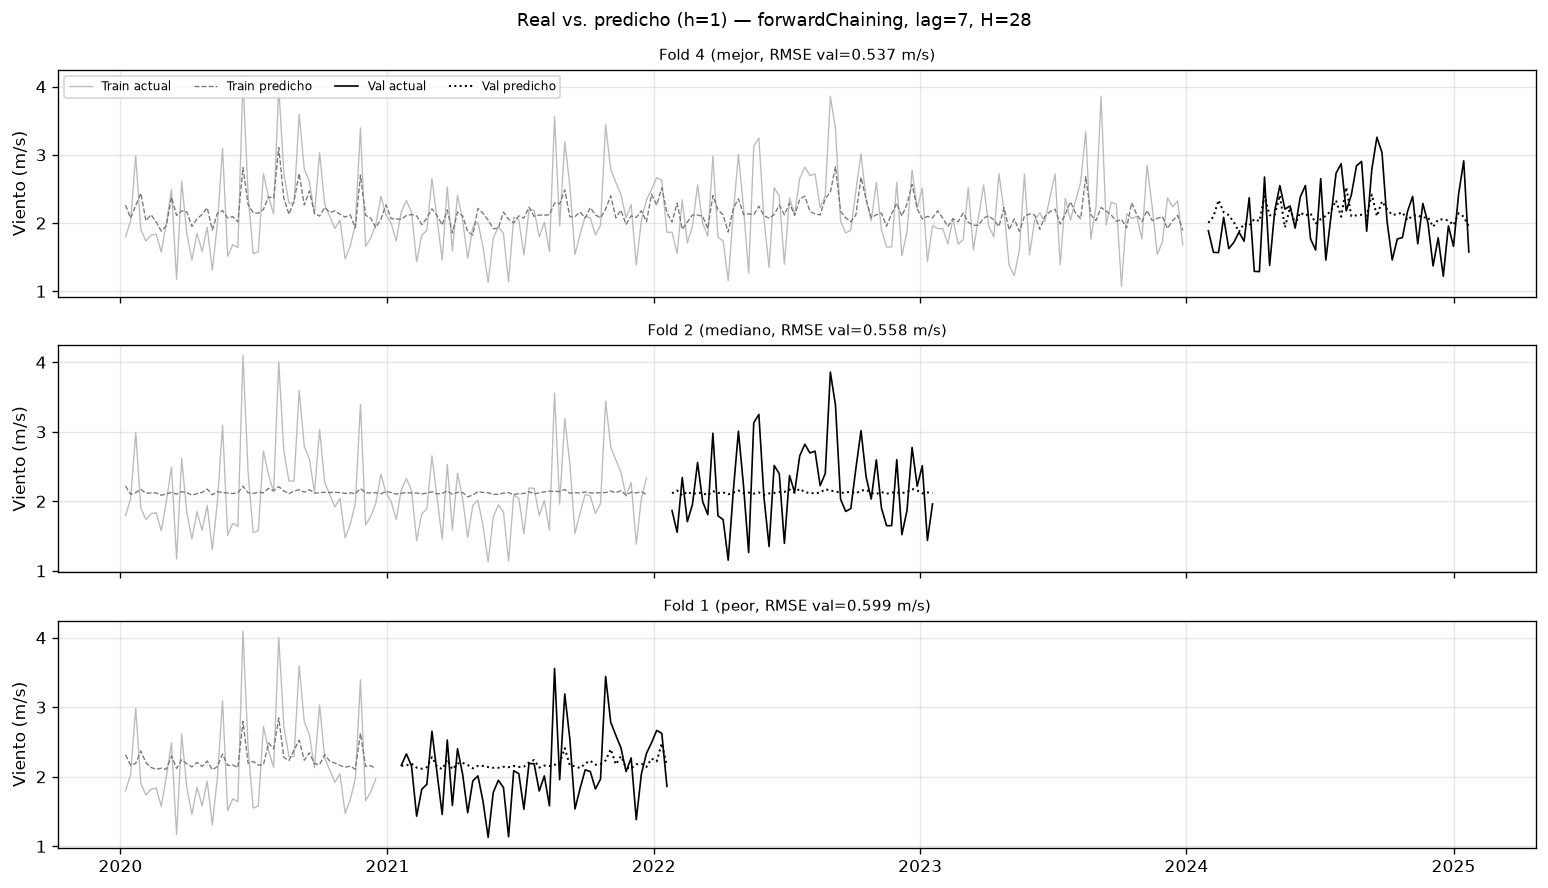

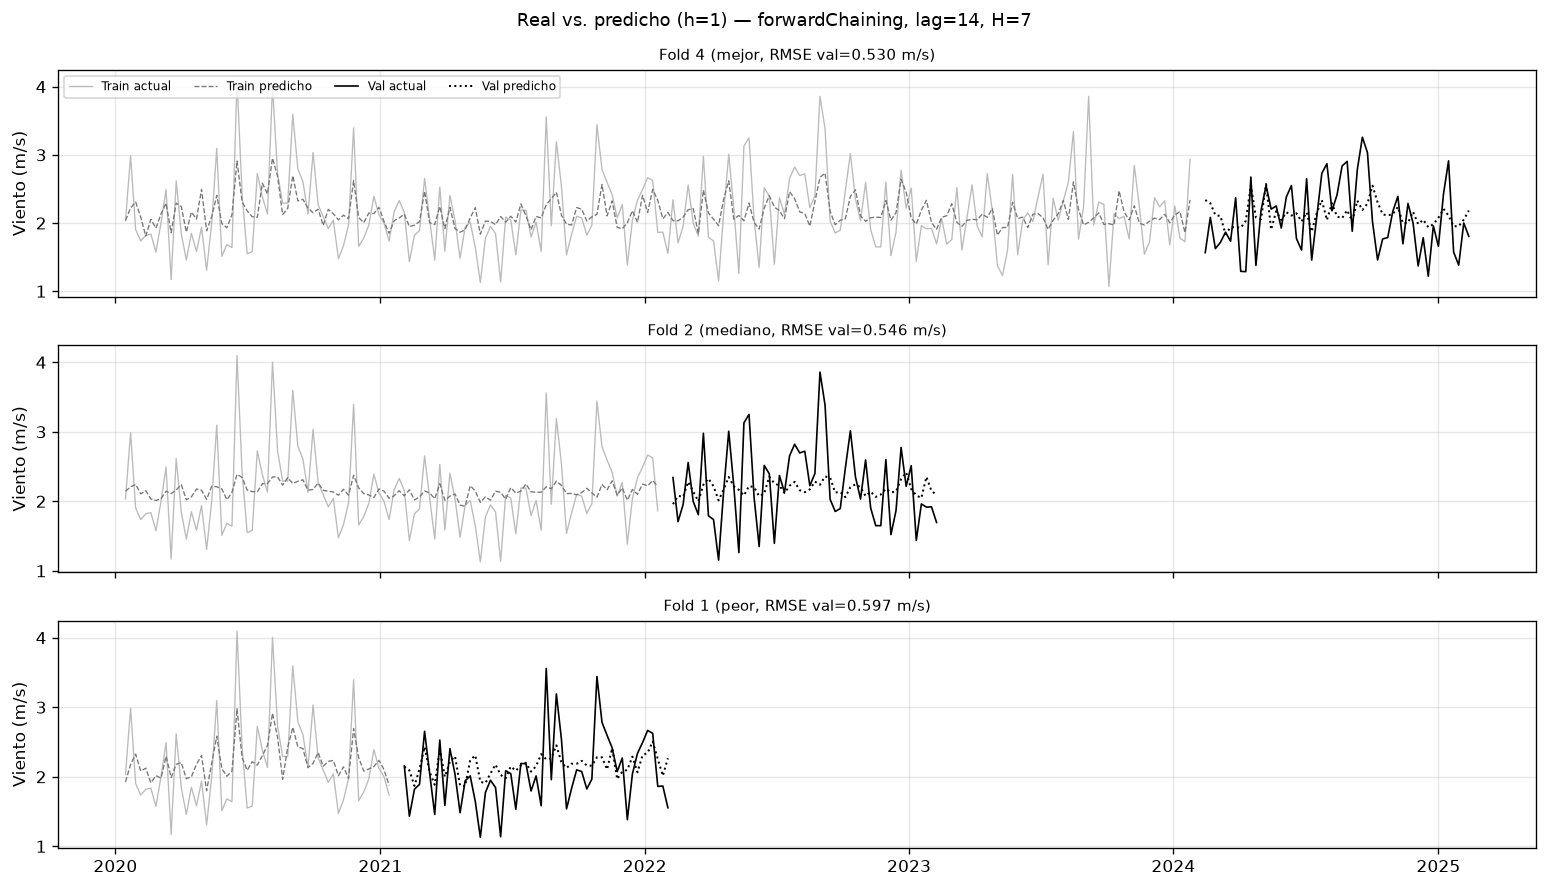

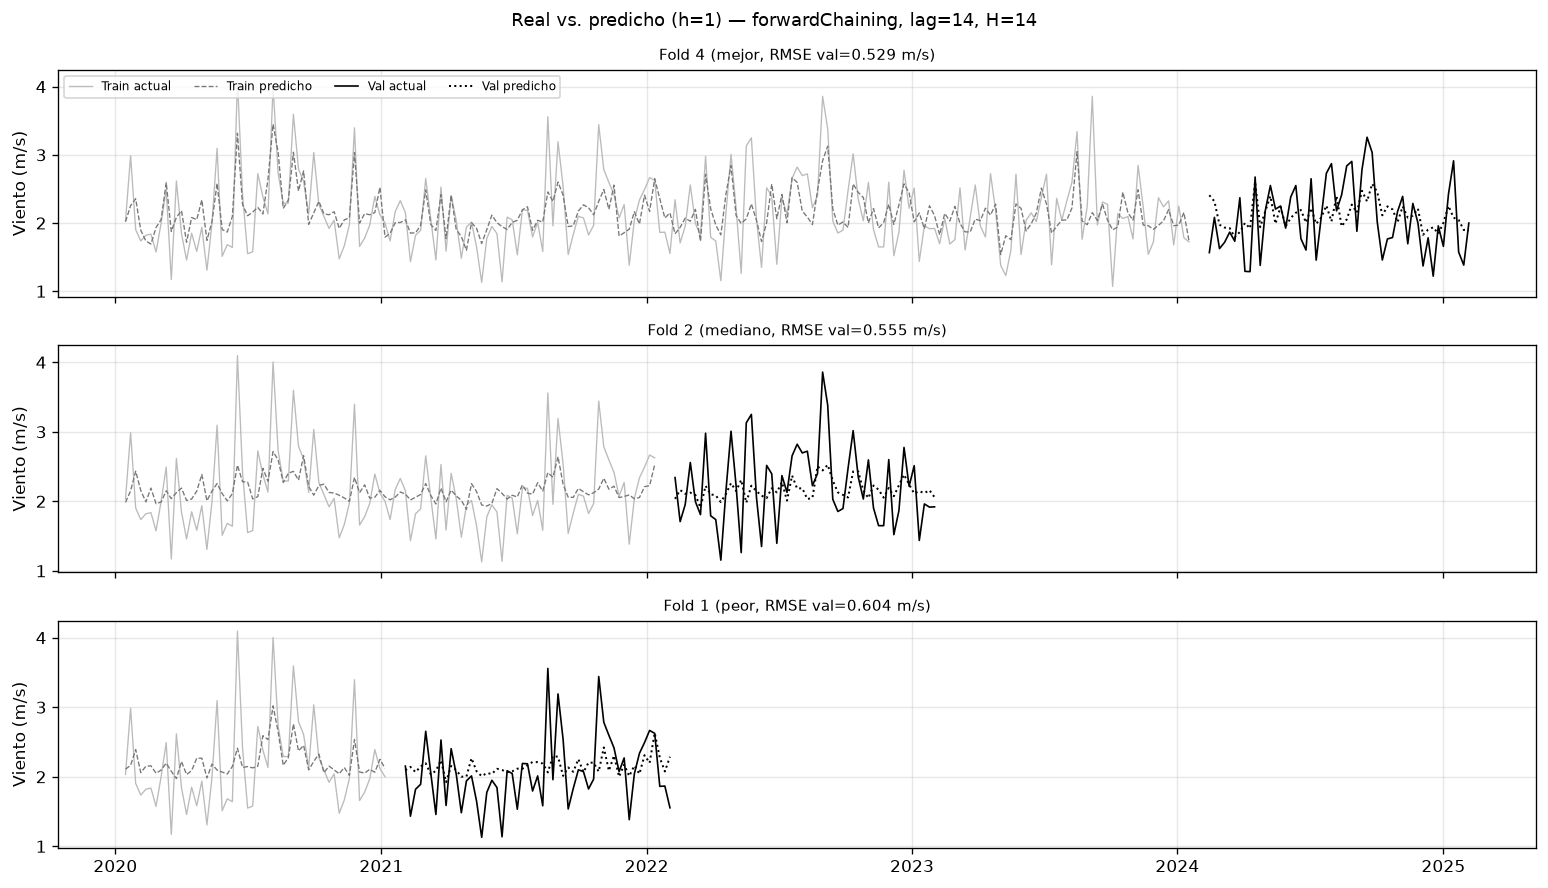

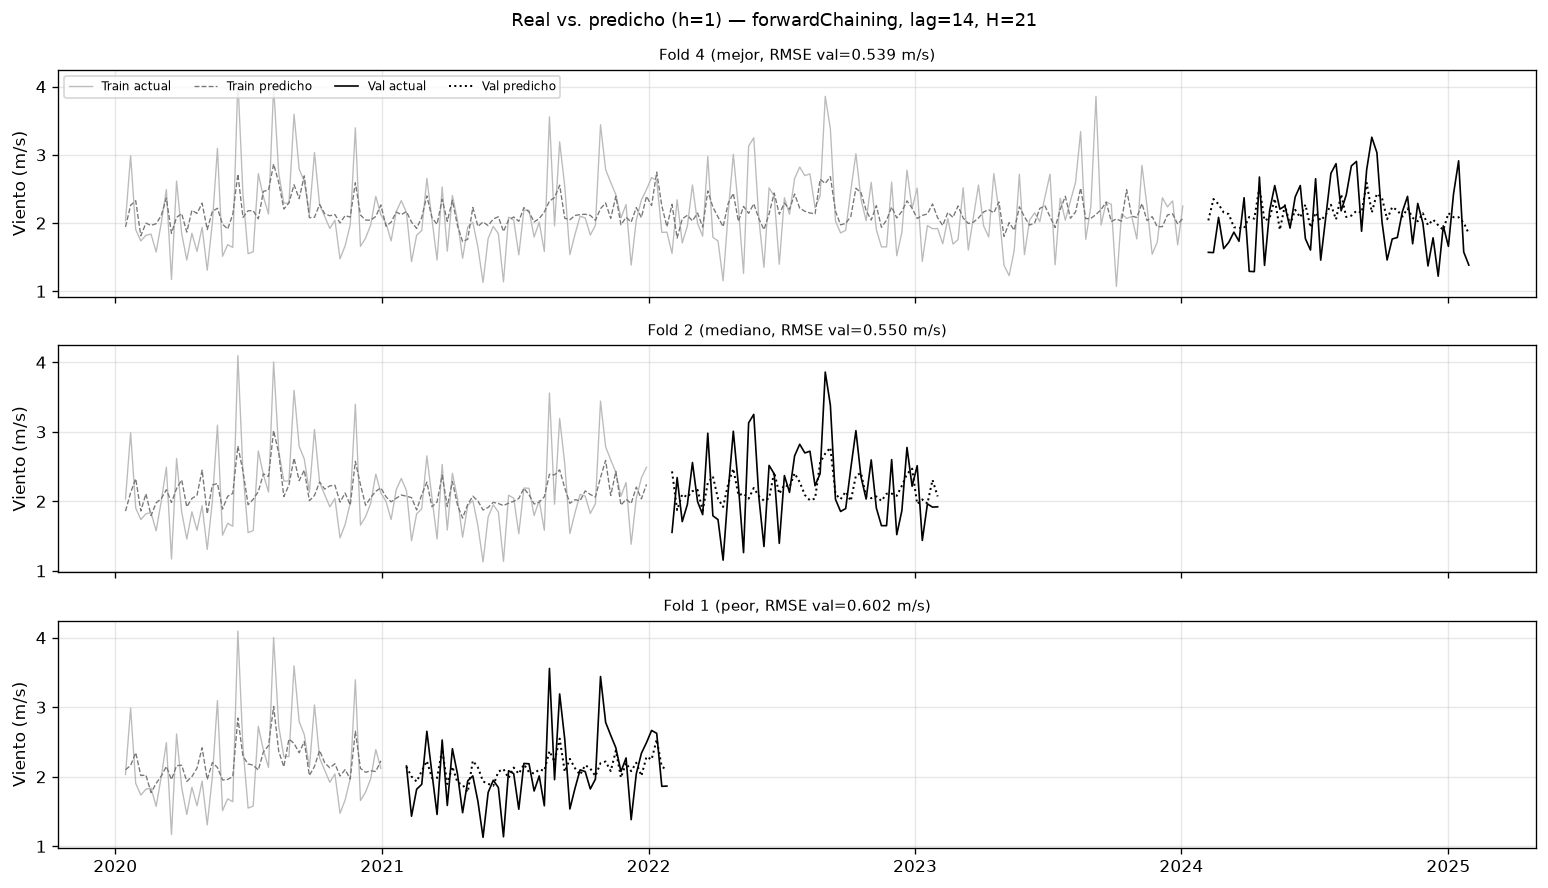

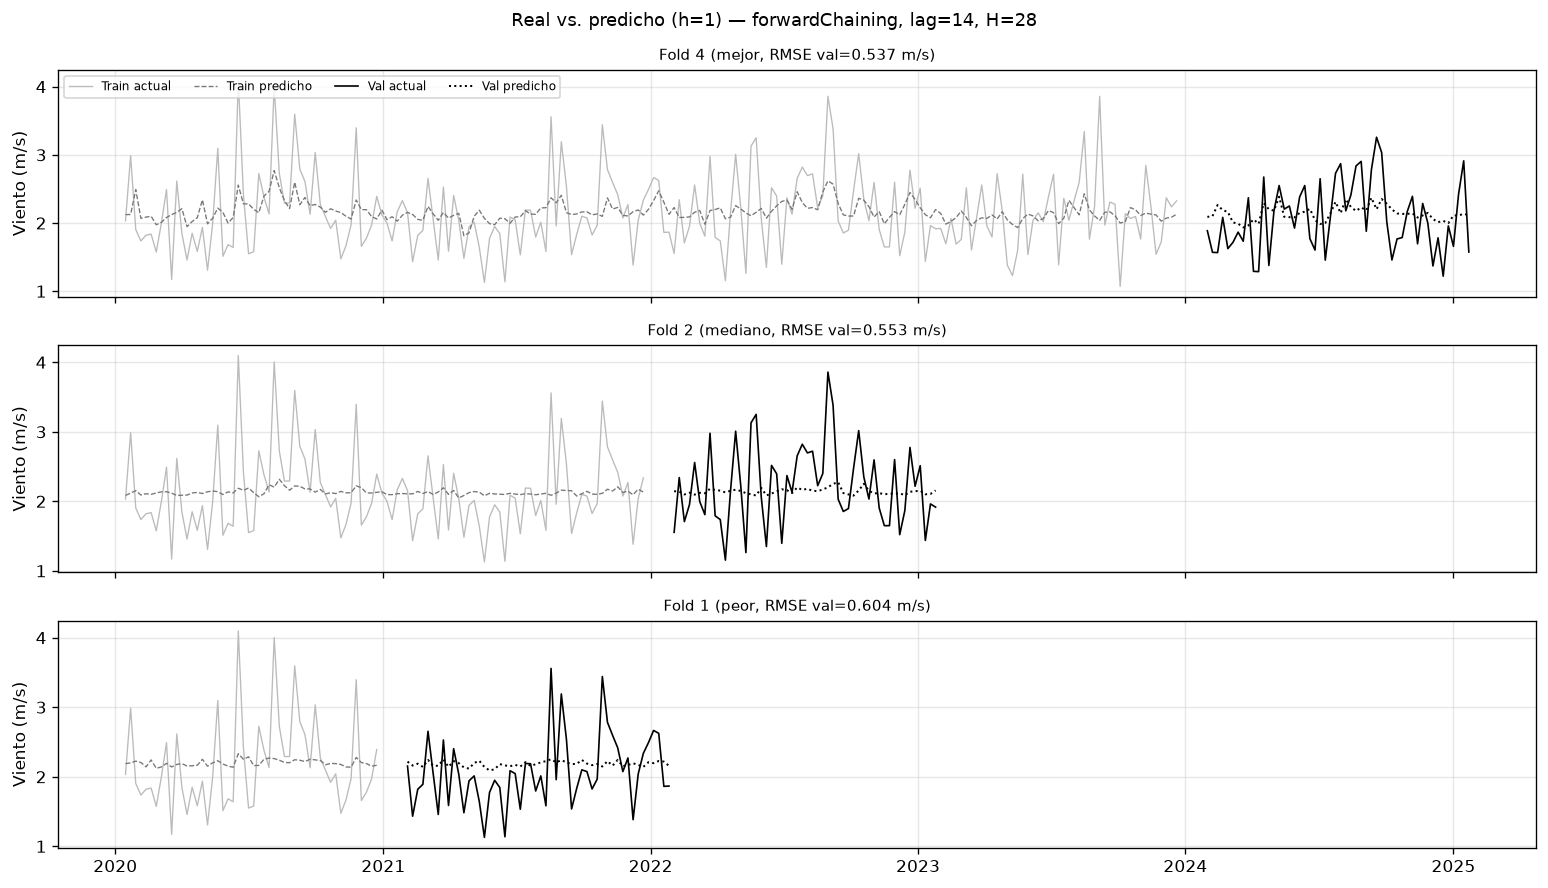

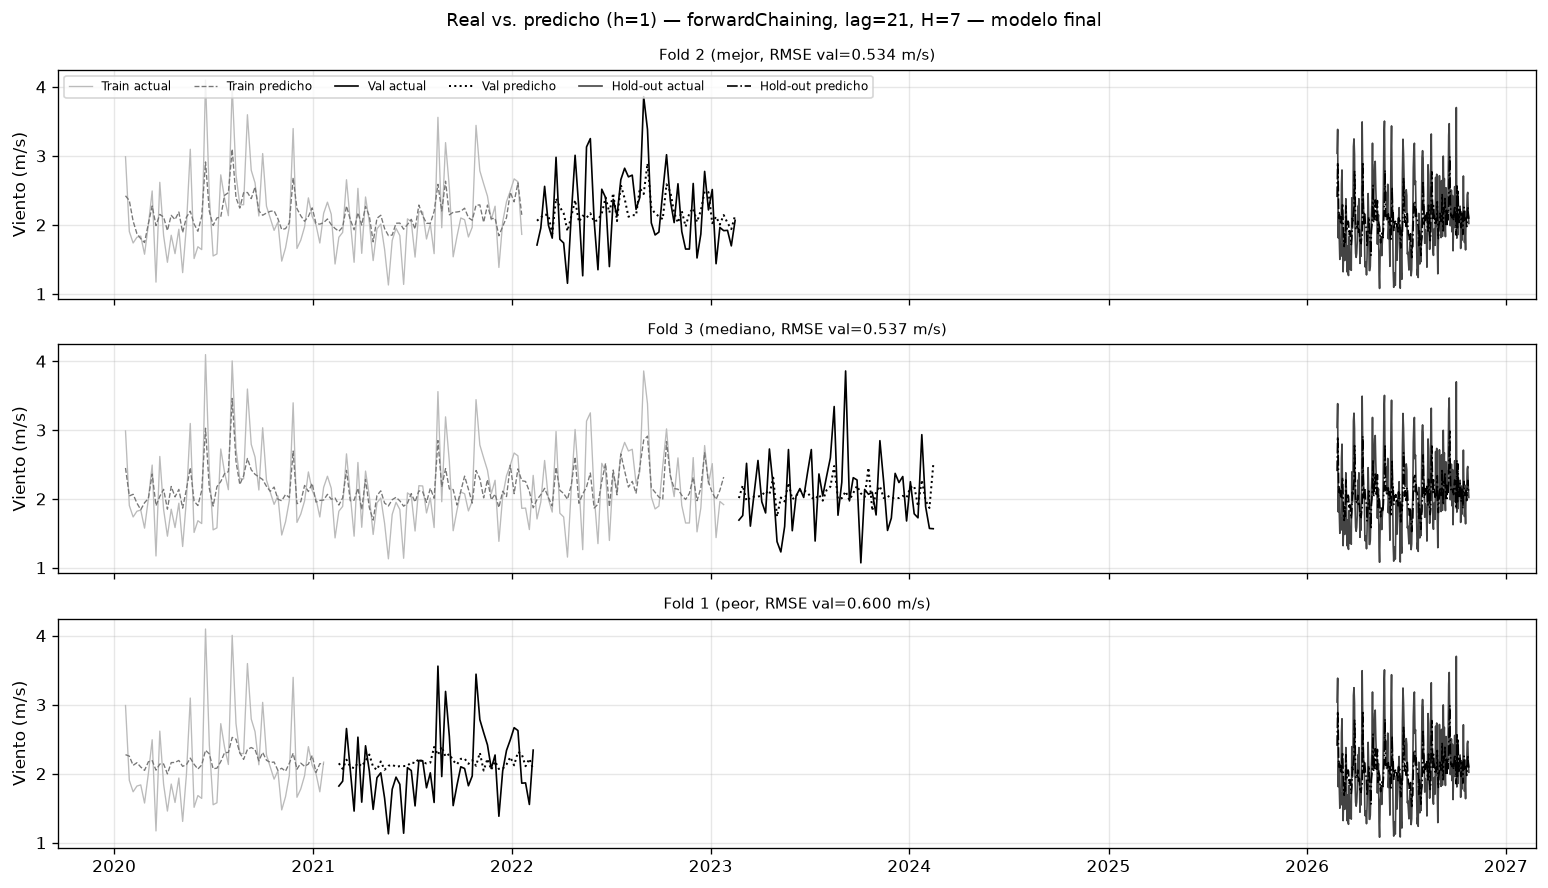

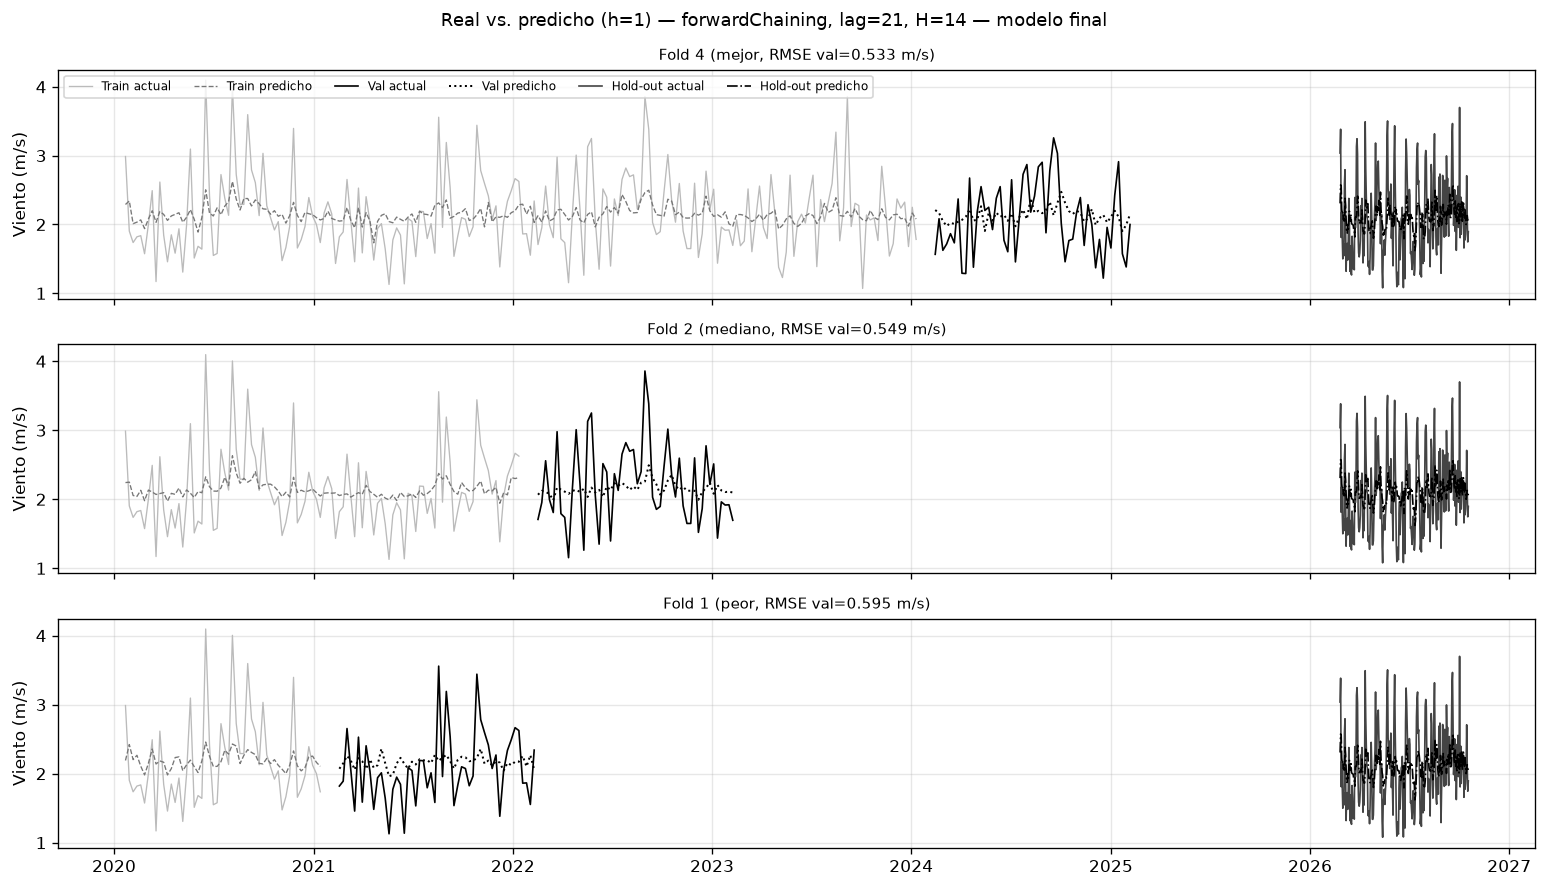

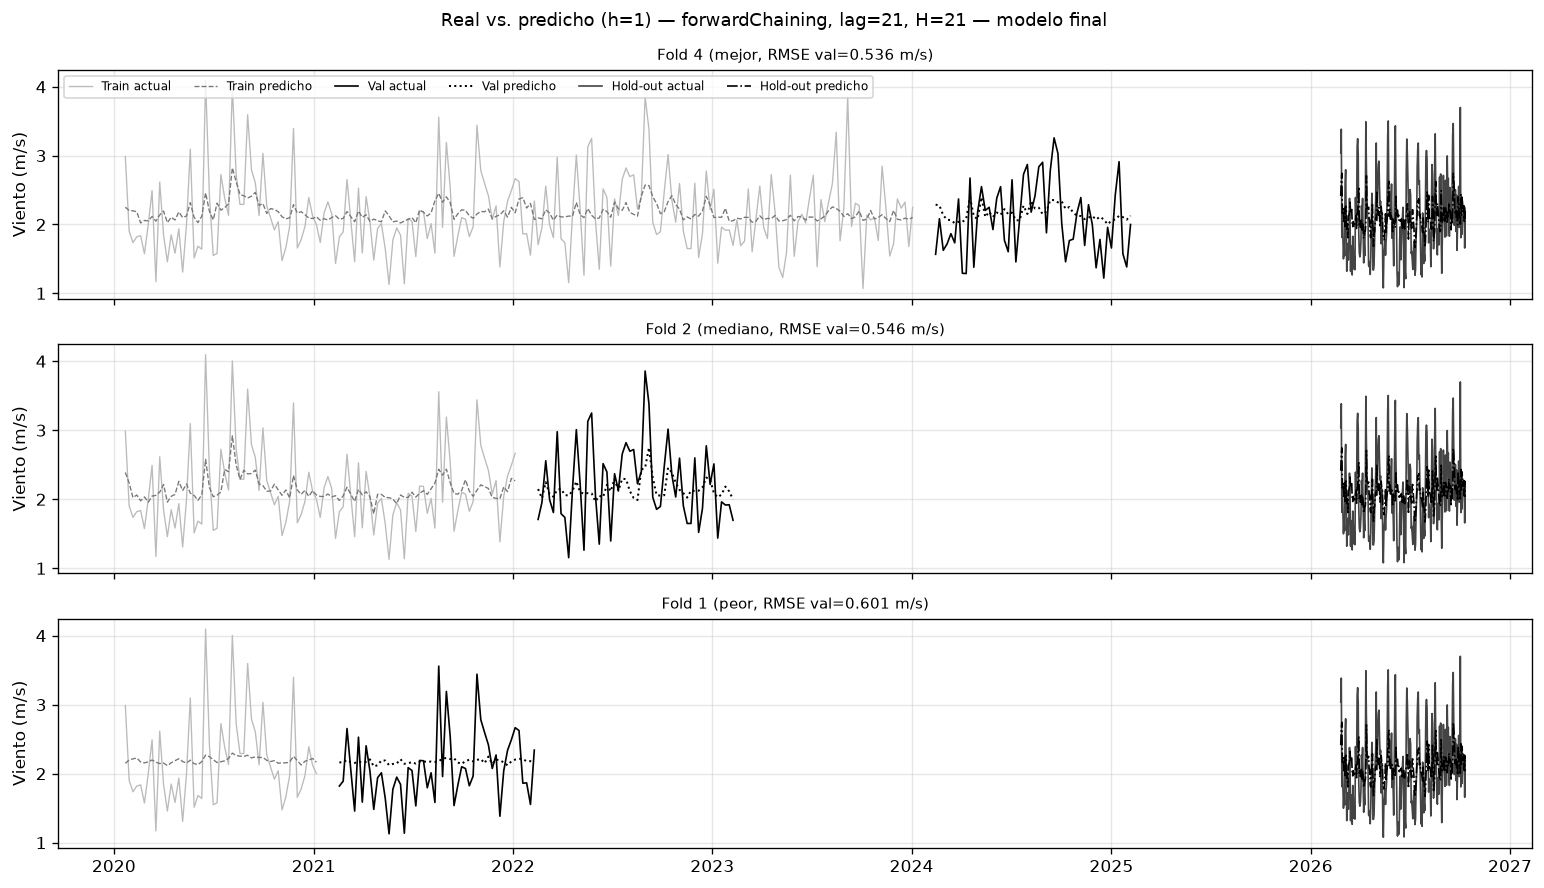

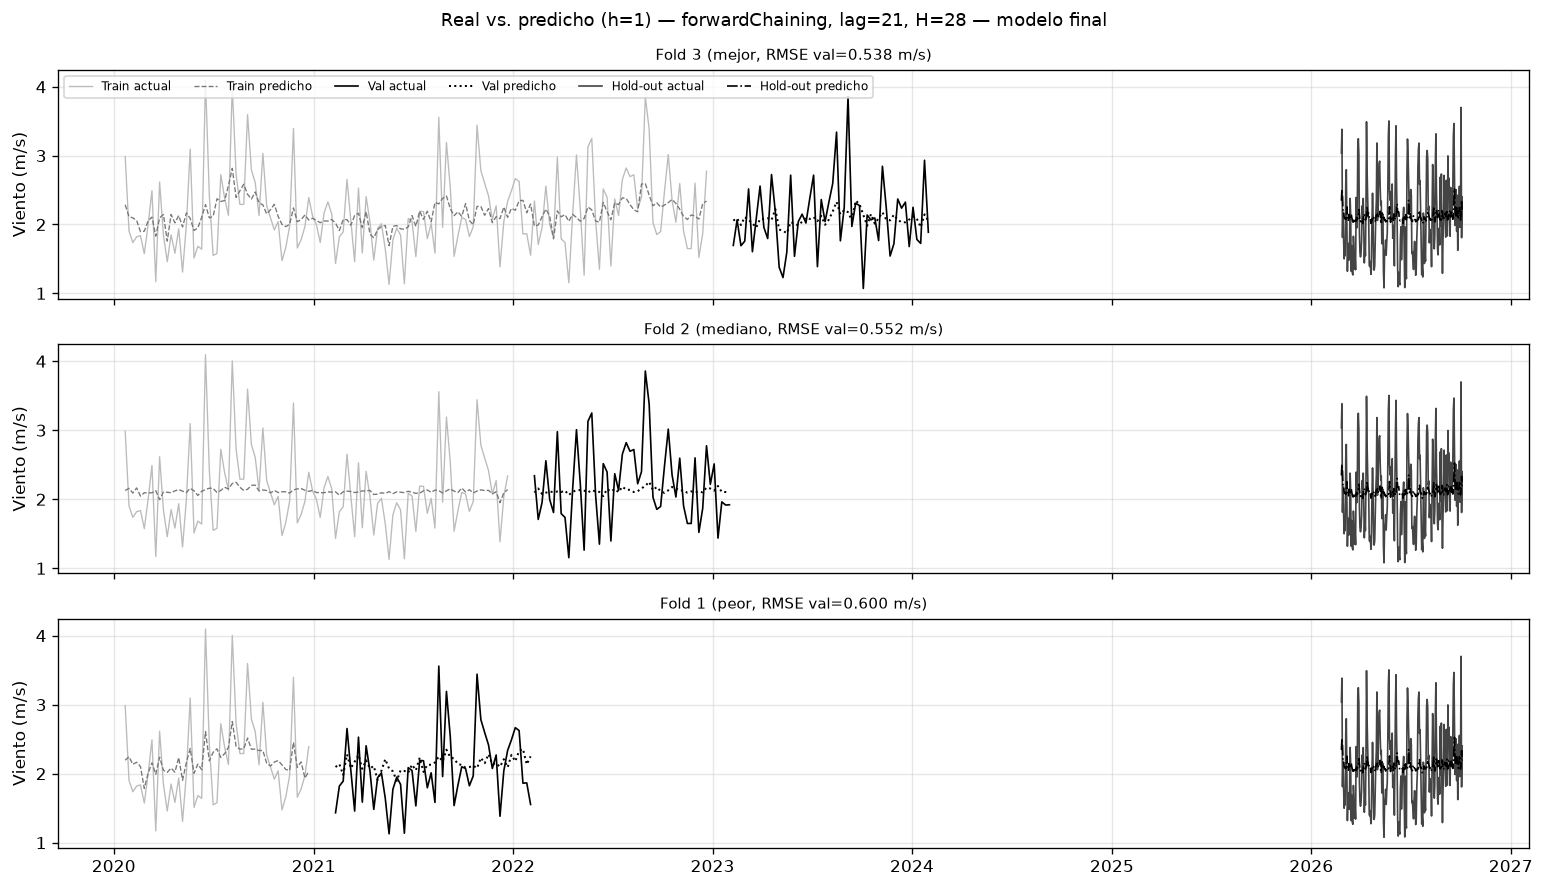

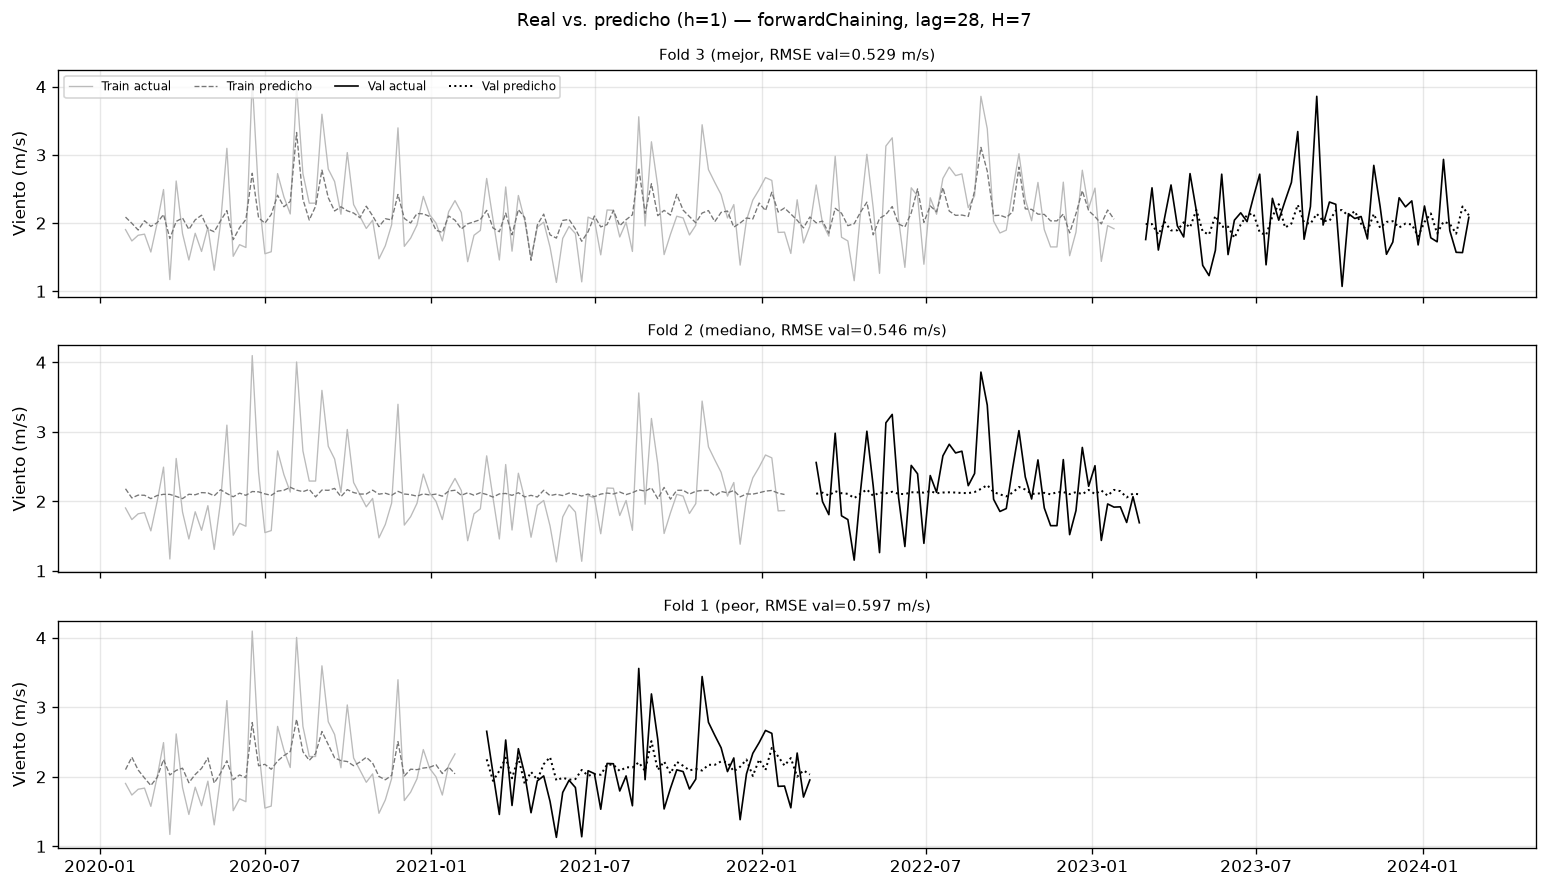

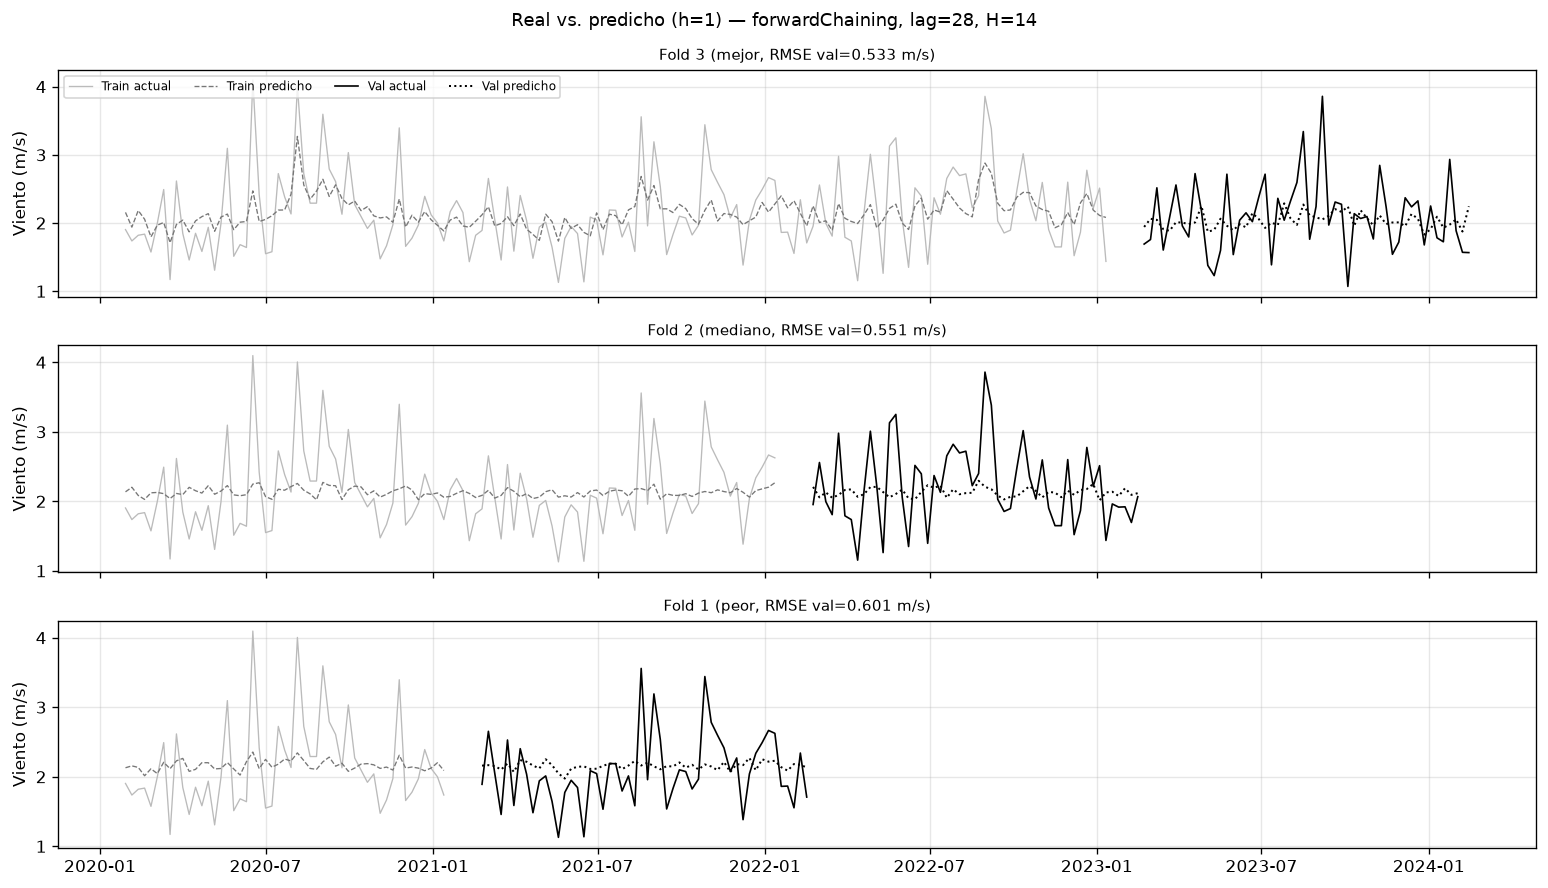

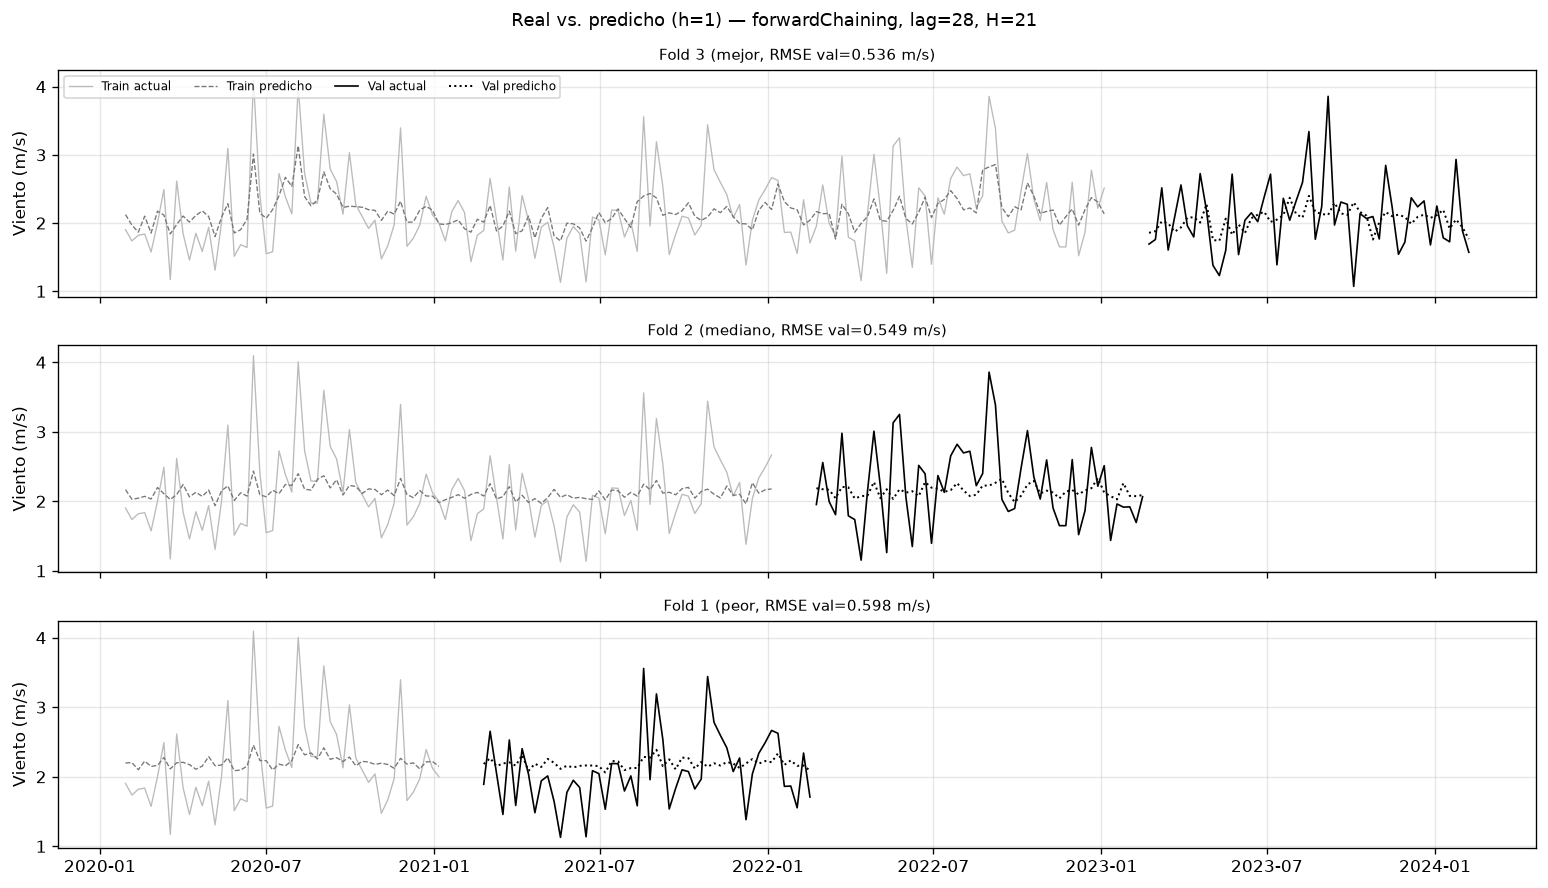

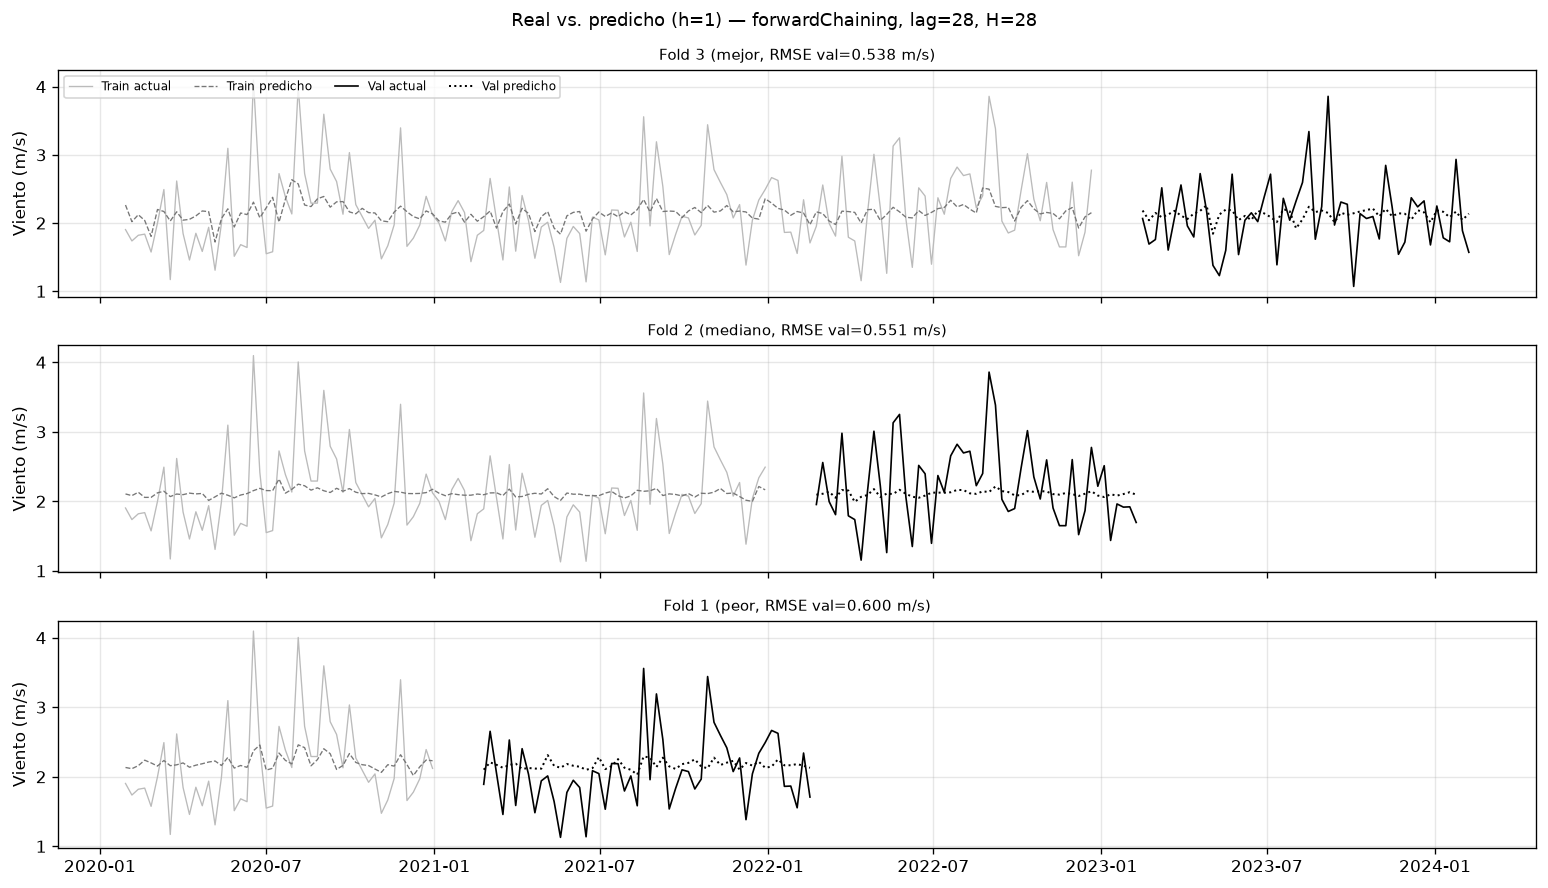

In [12]:
finales = {(int(r.lag), int(r.horizonte)) for r in ho_df.itertuples()}
for lag in LAGS_LIST:
    for H in HORIZONS_LIST:
        sub = fc_folds[(fc_folds.lag == lag) & (fc_folds.horizonte == H)].sort_values('rmse')
        elegidos = [('mejor', sub.iloc[0]), ('mediano', sub.iloc[len(sub) // 2]), ('peor', sub.iloc[-1])]
        fig, axes = plt.subplots(3, 1, figsize=(13, 7.5), sharex=True)
        for ax, (nombre, fila) in zip(axes, elegidos):
            p = preds_df[(preds_df.estrategia == 'forwardChaining') & (preds_df.lag == lag)
                         & (preds_df.horizonte == H) & (preds_df.fold == fila['fold'])]
            tr, va = p[p.conjunto == 'train'], p[p.conjunto == 'val']
            ax.plot(tr.fecha, tr.real, color='#bbbbbb', lw=0.8, label='Train actual')
            ax.plot(tr.fecha, tr.pred, color='#777777', lw=0.8, ls='--', label='Train predicho')
            ax.plot(va.fecha, va.real, color='black', lw=1.0, label='Val actual')
            ax.plot(va.fecha, va.pred, color='black', lw=1.2, ls=':', label='Val predicho')
            if (lag, H) in finales:
                ho = ho_pred_df[ho_pred_df.horizonte == H]
                ax.plot(ho.fecha, ho.real, color='#444444', lw=1.0, label='Hold-out actual')
                ax.plot(ho.fecha, ho.pred, color='black', lw=1.0, ls='-.', label='Hold-out predicho')
            ax.set_title(f'Fold {fila["fold"]} ({nombre}, RMSE val={fila["rmse"]:.3f} m/s)', fontsize=9)
            ax.set_ylabel('Viento (m/s)')
        axes[0].legend(fontsize=7, ncol=6, loc='upper left')
        sufijo = ' — modelo final' if (lag, H) in finales else ''
        plt.suptitle(f'Real vs. predicho (h=1) — forwardChaining, lag={lag}, H={H}{sufijo}', fontsize=11)
        plt.tight_layout()
        plt.savefig(os.path.join(FIGS_DIR, f'train_serie_lag{lag}_h{H}.png'), dpi=120, bbox_inches='tight')
        plt.show()

**Interpretación.** En las 16 figuras la predicción del primer paso sigue el nivel general del viento, pero con mucha menos variación que la serie real. En validación, la desviación estándar de lo predicho es el 24 % de la real y la correlación entre ambas es de 0,43 (promedio de los folds de Forward Chaining); en el hold-out esa proporción va del 13 % (H = 28) al 43 % (H = 7) y la correlación de 0,31 a 0,44. En entrenamiento la predicción también es suave, con una proporción del 28 %, una correlación de 0,66 y un RMSE de 0,49 m/s en el primer paso, muy cercano al de validación (0,50 m/s).

Esto quiere decir que el MLP es un pronosticador conservador y no memoriza: capta parte del movimiento lento de la serie y se acerca a la media cuando no tiene evidencia, que es lo que minimiza el error cuadrático cuando la señal es débil. Los picos quedan por encima de lo predicho y los valles por debajo. Es probable que el dropout de 0,5 y EarlyStopping refuercen ese comportamiento, porque penalizan las predicciones que se alejan de la media sin suficiente respaldo en los datos.

Con base en esto, se propone como trabajo futuro explorar tasas de dropout menores e incorporar variables derivadas de la fecha, como el día del año en seno y coseno, que el enunciado admite al hablar de "fecha y valores observados", para capturar la estacionalidad que hoy queda en los residuos.

---

## 11. Conclusiones

1. Las tres estrategias de `timeseries-cv` se aplicaron en las 16 combinaciones lag × horizonte. Como la versión 0.1.5 entrega folds de una sola ventana de validación en Forward Chaining y K-Fold, esos folds se agruparon en cinco, con purga, para poder calcular el RMSE por horizonte y la prueba BDS por fold.
2. Forward Chaining es la estrategia final: es la única que respeta la causalidad, obtuvo el menor RMSE de validación (0,5614 m/s) y sus residuos no rechazan la independencia en el 95 % de los folds. Sus diferencias con Group K-Fold y K-Fold (menos de 0,008 m/s) son menores que la variación entre folds, de modo que el sesgo optimista de esas estrategias no se reflejó en el error.
3. El MLP mejora al `MLPRegressor` de referencia en un 16,7 % y a la persistencia en cerca de un 25 %, pero a la media solo en un 1,3 % en validación, y en el hold-out queda entre un 0,2 % y un 2,0 % por debajo de ella (cuaderno 4, sección 9). La información útil se concentra en los primeros pasos del horizonte.
4. El RMSE del hold-out (0,567 a 0,575 m/s) es entre 1,2 % y 4,1 % mayor que el de validación, lo que respalda la ausencia de fuga de información en el protocolo.
5. El lag casi no influye (diferencias de 0,003 m/s como máximo) y el horizonte sí, aunque de forma moderada. Las mejoras más prometedoras son reducir la tasa de dropout e incorporar la estacionalidad a partir de la fecha.

## Referencias

- Bergmeir, C., & Benítez, J. M. (2012). On the use of cross-validation for time series predictor evaluation. *Information Sciences*, 191, 192–213.
- Prechelt, L. (1998). Early stopping — but when? En *Neural Networks: Tricks of the Trade* (pp. 55–69). Springer.
- Tashman, L. J. (2000). Out-of-sample tests of forecasting accuracy: an analysis and review. *International Journal of Forecasting*, 16(4), 437–450.